# Подключение к БД и настройки

In [1]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sqlalchemy import create_engine, text
from dotenv import load_dotenv
from pathlib import Path

# Определяем корень проекта 
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent 
print(NOTEBOOK_DIR)
print(PROJECT_ROOT)

# Путь к .env
env_path = PROJECT_ROOT / ".env"
print(f"📁 Ищем файл .env по пути: {env_path}")

if not env_path.exists():
    raise FileNotFoundError(
        f"❌ Файл .env не найден!\n"
        f"Убедитесь, что он лежит в корне проекта: {PROJECT_ROOT}"
    )

# Загружаем переменные окружения
load_dotenv(env_path)

DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")

# Создаем engine
engine = create_engine(f"postgresql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

# Тест подключения
with engine.connect() as conn:
    conn.execute(text("SELECT 1"))
    
print("\n✅ Подключение к PostgreSQL успешно установлено!")


warnings.filterwarnings('ignore')

# Настройка стиля
sns.set_style('whitegrid')
sns.set_palette('husl')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

C:\Users\User\Desktop\Учеба\ПРОЕКТ_ПРОГНОЗ_ВОЗНИКНОВЕНИЯ_ДЕФЕЦИТА_ЛК_СРЕДСТВ\Проект\drug-deficit-predictor\notebooks
C:\Users\User\Desktop\Учеба\ПРОЕКТ_ПРОГНОЗ_ВОЗНИКНОВЕНИЯ_ДЕФЕЦИТА_ЛК_СРЕДСТВ\Проект\drug-deficit-predictor
📁 Ищем файл .env по пути: C:\Users\User\Desktop\Учеба\ПРОЕКТ_ПРОГНОЗ_ВОЗНИКНОВЕНИЯ_ДЕФЕЦИТА_ЛК_СРЕДСТВ\Проект\drug-deficit-predictor\.env

✅ Подключение к PostgreSQL успешно установлено!


# ЗАГРУЗКА ИСХОДНИКОВ

In [2]:
# Берём только актуальные препараты
query = """
SELECT 
    id_original,
    name_trade,
    standard_inn,
    smnn_code,
    code_atc,
    essential_medicines,
    narcotic_psychotropic,
    actual,
    oksm_code,
    country,
    name_producer,
    date_registration,
    okei_code,
    klp_code,
    ktru_code,
    standard_form,
    standard_doze,
    number_registration
FROM raw_data.drug_products
WHERE actual = TRUE;
"""

df = pd.read_sql(query, engine)
df 

,id_original,name_trade,standard_inn,smnn_code,code_atc,essential_medicines,narcotic_psychotropic,actual,oksm_code,country,name_producer,date_registration,okei_code,klp_code,ktru_code,standard_form,standard_doze,number_registration
0,1083632,Желчегонный сбор №3,КАЛЕНДУЛЫ ЛЕКАРСТВЕННОЙ ЦВЕТКИ+МЯТЫ ПЕРЕЧНОЙ Л...,21.20.10.113-000015-1-00056-0000000000000,None,False,False,True,643.0,РОССИЯ,ООО ПКФ ФИТОФАРМ,2026-04-29,163,21.20.10.113-000015-1-00056-2000001924732,None,СБОР-ПОРОШОК,None,ЛП-№(014704)-(РГ-RU)
1,1084512,Пикопреп,ЛИМОННАЯ КИСЛОТА+МАГНИЯ ОКСИД+НАТРИЯ ПИКОСУЛЬФАТ,21.20.10.115-000045-1-00023-0000000000000,A06AB58,False,False,True,156.0,КИТАЙ,"ФЕРРИНГ ФАРМАСЬЮТИКАЛЗ КО., ЛТД.",2026-04-14,163,21.20.10.115-000045-1-00023-2000001929890,None,ПОРОШОК ДЛЯ ПРИГОТОВЛЕНИЯ РАСТВОРА ДЛЯ ПРИЕМА ...,12 г+3.5 г+10 мг,ЛП-№(014464)-(РГ-RU)
2,1084513,Пикопреп,ЛИМОННАЯ КИСЛОТА+МАГНИЯ ОКСИД+НАТРИЯ ПИКОСУЛЬФАТ,21.20.10.115-000045-1-00023-0000000000000,A06AB58,False,False,True,156.0,КИТАЙ,"ФЕРРИНГ ФАРМАСЬЮТИКАЛЗ КО., ЛТД.",2026-04-14,163,21.20.10.115-000045-1-00023-2000001929891,None,ПОРОШОК ДЛЯ ПРИГОТОВЛЕНИЯ РАСТВОРА ДЛЯ ПРИЕМА ...,12 г+3.5 г+10 мг,ЛП-№(014464)-(РГ-RU)
3,1088543,Андрогель,ТЕСТОСТЕРОН,21.20.10.173-000050-1-00130-0000000000000,G03BA03,True,False,True,56.0,БЕЛЬГИЯ,БЕЗЕН МЕНУФЕКЧУРИНГ БЕЛДЖИУМ С.А.,2026-04-10,163,21.20.10.173-000050-1-00130-2000001929261,None,ГЕЛЬ ДЛЯ НАРУЖНОГО ПРИМЕНЕНИЯ,16.2 мг/г,ЛП-№(000983)-(ГП-RU)
4,1088544,Андрогель,ТЕСТОСТЕРОН,21.20.10.173-000050-1-00130-0000000000000,G03BA03,True,False,True,250.0,ФРАНЦИЯ,ЛАБОРАТОРИИ БЕЗЕН ИНТЕРНАСИОНАЛЬ,2026-04-10,163,21.20.10.173-000050-1-00130-2000001929260,None,ГЕЛЬ ДЛЯ НАРУЖНОГО ПРИМЕНЕНИЯ,16.2 мг/г,ЛП-№(000983)-(ГП-RU)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
604344,541567,Метопролол,МЕТОПРОЛОЛ,21.20.10.146-000002-1-00121-0000000000000,C07AB02,True,False,True,643.0,РОССИЯ,ООО ОЗОН ФАРМ,2024-03-29,796,21.20.10.146-000002-1-00121-2000001339706,21.20.10.146-000002-1-00121-0000000000000,ТАБЛЕТКИ,100 мг,ЛП-№(005030)-(РГ-RU)
604345,588820,Амлодипин,АМЛОДИПИН,21.20.10.147-000001-1-00069-0000000000000,C08CA01,True,False,True,643.0,РОССИЯ,ООО ОЗОН ФАРМ,2024-06-28,796,21.20.10.147-000001-1-00069-2000001386080,21.20.10.147-000001-1-00069-0000000000000,ТАБЛЕТКИ,10 мг,ЛП-№(006071)-(РГ-RU)
604346,394838,Амброксол,АМБРОКСОЛ,21.20.10.255-000002-1-00143-0000000000000,R05CB06,True,False,True,643.0,РОССИЯ,ООО ОЗОН ФАРМ,2022-09-08,796,21.20.10.255-000002-1-00143-2000001188403,21.20.10.255-000002-1-00143-0000000000000,ТАБЛЕТКИ,30 мг,ЛП-№(001188)-(РГ-RU)
604347,425105,Антистен МВ,ТРИМЕТАЗИДИН,21.20.10.141-000009-1-00139-0000000000000,C01EB15,False,False,True,643.0,РОССИЯ,ООО ОЗОН,2022-05-13,796,21.20.10.141-000009-1-00139-2000001218281,21.20.10.141-000009-1-00139-0000000000000,"ТАБЛЕТКИ С ПРОЛОНГИРОВАННЫМ ВЫСВОБОЖДЕНИЕМ, ПО...",35 мг,ЛП-№(000782)-(РГ-RU)


# Первичный осмотр 

In [3]:
print('ПЕРВЫЕ 5 СТРОК')
display(df.head())

print("\nСТРУКТУРА DF")
df.info(memory_usage='deep')

# Размер
print(f"\n📐 Форма (строк, колонок): {df.shape}")

print("\nОПИСАТЕЛЬНАЯ СТАТИСТИКА (числовые колонки)")
display(df.describe())

print("\nОПИСАТЕЛЬНАЯ СТАТИСТИКА (все колонки)")
display(df.describe(include='all'))

ПЕРВЫЕ 5 СТРОК


,id_original,name_trade,standard_inn,smnn_code,code_atc,essential_medicines,narcotic_psychotropic,actual,oksm_code,country,name_producer,date_registration,okei_code,klp_code,ktru_code,standard_form,standard_doze,number_registration
0,1083632,Желчегонный сбор №3,КАЛЕНДУЛЫ ЛЕКАРСТВЕННОЙ ЦВЕТКИ+МЯТЫ ПЕРЕЧНОЙ Л...,21.20.10.113-000015-1-00056-0000000000000,None,False,False,True,643.0,РОССИЯ,ООО ПКФ ФИТОФАРМ,2026-04-29,163,21.20.10.113-000015-1-00056-2000001924732,None,СБОР-ПОРОШОК,None,ЛП-№(014704)-(РГ-RU)
1,1084512,Пикопреп,ЛИМОННАЯ КИСЛОТА+МАГНИЯ ОКСИД+НАТРИЯ ПИКОСУЛЬФАТ,21.20.10.115-000045-1-00023-0000000000000,A06AB58,False,False,True,156.0,КИТАЙ,"ФЕРРИНГ ФАРМАСЬЮТИКАЛЗ КО., ЛТД.",2026-04-14,163,21.20.10.115-000045-1-00023-2000001929890,None,ПОРОШОК ДЛЯ ПРИГОТОВЛЕНИЯ РАСТВОРА ДЛЯ ПРИЕМА ...,12 г+3.5 г+10 мг,ЛП-№(014464)-(РГ-RU)
2,1084513,Пикопреп,ЛИМОННАЯ КИСЛОТА+МАГНИЯ ОКСИД+НАТРИЯ ПИКОСУЛЬФАТ,21.20.10.115-000045-1-00023-0000000000000,A06AB58,False,False,True,156.0,КИТАЙ,"ФЕРРИНГ ФАРМАСЬЮТИКАЛЗ КО., ЛТД.",2026-04-14,163,21.20.10.115-000045-1-00023-2000001929891,None,ПОРОШОК ДЛЯ ПРИГОТОВЛЕНИЯ РАСТВОРА ДЛЯ ПРИЕМА ...,12 г+3.5 г+10 мг,ЛП-№(014464)-(РГ-RU)
3,1088543,Андрогель,ТЕСТОСТЕРОН,21.20.10.173-000050-1-00130-0000000000000,G03BA03,True,False,True,56.0,БЕЛЬГИЯ,БЕЗЕН МЕНУФЕКЧУРИНГ БЕЛДЖИУМ С.А.,2026-04-10,163,21.20.10.173-000050-1-00130-2000001929261,None,ГЕЛЬ ДЛЯ НАРУЖНОГО ПРИМЕНЕНИЯ,16.2 мг/г,ЛП-№(000983)-(ГП-RU)
4,1088544,Андрогель,ТЕСТОСТЕРОН,21.20.10.173-000050-1-00130-0000000000000,G03BA03,True,False,True,250.0,ФРАНЦИЯ,ЛАБОРАТОРИИ БЕЗЕН ИНТЕРНАСИОНАЛЬ,2026-04-10,163,21.20.10.173-000050-1-00130-2000001929260,None,ГЕЛЬ ДЛЯ НАРУЖНОГО ПРИМЕНЕНИЯ,16.2 мг/г,ЛП-№(000983)-(ГП-RU)



СТРУКТУРА DF
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 604349 entries, 0 to 604348
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   id_original            604349 non-null  int64  
 1   name_trade             604349 non-null  object 
 2   standard_inn           604349 non-null  object 
 3   smnn_code              604349 non-null  object 
 4   code_atc               595109 non-null  object 
 5   essential_medicines    604349 non-null  bool   
 6   narcotic_psychotropic  604349 non-null  bool   
 7   actual                 604349 non-null  bool   
 8   oksm_code              604349 non-null  float64
 9   country                604349 non-null  object 
 10  name_producer          604349 non-null  object 
 11  date_registration      604349 non-null  object 
 12  okei_code              604349 non-null  int64  
 13  klp_code               604349 non-null  object 
 14  ktru_code             

,id_original,oksm_code,okei_code
count,6.043490e+05,604349.000000,604349.000000
mean,8.909674e+05,614.631091,557.051881
std,3.618426e+05,107.833748,570.639566
min,1.940000e+02,32.000000,111.000000
25%,6.692650e+05,643.000000,111.000000
50%,8.446730e+05,643.000000,796.000000
75%,1.008072e+06,643.000000,796.000000
max,1.911030e+06,860.000000,9920.000000



ОПИСАТЕЛЬНАЯ СТАТИСТИКА (все колонки)


,id_original,name_trade,standard_inn,smnn_code,code_atc,essential_medicines,narcotic_psychotropic,actual,oksm_code,country,name_producer,date_registration,okei_code,klp_code,ktru_code,standard_form,standard_doze,number_registration
count,6.043490e+05,604349,604349,604349,595109,604349,604349,604349,604349.000000,604349,604349,604349,604349.000000,604349,603053,604349,569703,604349
unique,NaN,12248,3328,7672,2527,2,2,1,NaN,77,2347,3536,NaN,604349,7590,432,1912,29301
top,NaN,Глюкоза,ЭТАНОЛ,21.20.10.134-000013-1-00036-0000000000000,B05BB;B05BB01,True,False,True,NaN,РОССИЯ,ООО ОЗОН,2025-02-07,NaN,21.20.10.147-000001-1-00044-2000001387122,21.20.10.134-000013-1-00036-0000000000000,"ТАБЛЕТКИ, ПОКРЫТЫЕ ОБОЛОЧКОЙ",10 мг,ЛП-№(008746)-(РГ-RU)
freq,NaN,6871,14217,5286,10036,347187,601994,604349,NaN,528431,47385,5217,NaN,1,5286,167802,29192,5040
mean,8.909674e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,614.631091,NaN,NaN,NaN,557.051881,NaN,NaN,NaN,NaN,NaN
std,3.618426e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,107.833748,NaN,NaN,NaN,570.639566,NaN,NaN,NaN,NaN,NaN
min,1.940000e+02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.000000,NaN,NaN,NaN,111.000000,NaN,NaN,NaN,NaN,NaN
25%,6.692650e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,643.000000,NaN,NaN,NaN,111.000000,NaN,NaN,NaN,NaN,NaN
50%,8.446730e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,643.000000,NaN,NaN,NaN,796.000000,NaN,NaN,NaN,NaN,NaN
75%,1.008072e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,643.000000,NaN,NaN,NaN,796.000000,NaN,NaN,NaN,NaN,NaN


# Анализ пропусков 

,Пропусков,Процент
standard_doze,34646,5.73
code_atc,9240,1.53
ktru_code,1296,0.21


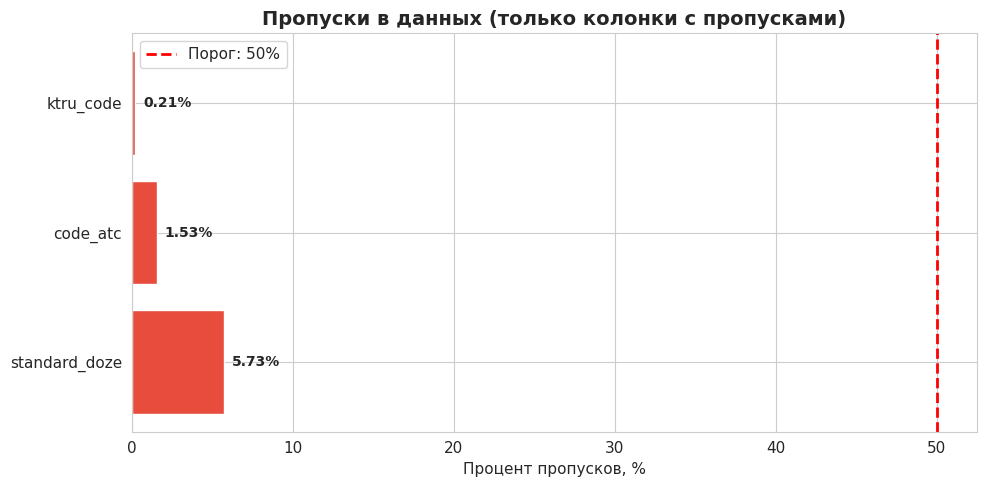


ЗАМАСКИРОВАННЫЕ ПРОПУСКИ
  code_atc == "~": 0 записей
  oksm_code == "не число": 0 записей


In [4]:
null_counts = df.isnull().sum()
null_pct = (df.isnull().sum() / len(df) * 100).round(2)

# Собираем в удобную таблицу 
null_df = pd.DataFrame({
    'Пропусков': null_counts,
    'Процент': null_pct
}).sort_values('Пропусков', ascending=False)

# Показываем только колнки с пропусками 
null_df = null_df[null_df['Пропусков'] > 0]
display(null_df)

# Визуализация пропусков 
if len(null_df) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.barh(null_df.index, null_df['Процент'], color='#e74c3c')
    ax.set_xlabel('Процент пропусков, %')
    ax.set_title('Пропуски в данных (только колонки с пропусками)', 
                 fontsize=14, fontweight='bold')
    
    for bar, pct in zip(bars, null_df['Процент']):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                f'{pct}%', va='center', fontsize=10, fontweight='bold')
    
    ax.axvline(x=50, color='red', linestyle='--', linewidth=2, 
               label='Порог: 50%')
    ax.legend()
    
    plt.tight_layout()
    # plt.savefig(f'{NOTEBOOK_DIR}/07_missing_values.png', dpi=100, bbox_inches='tight')
    plt.show()
else:
    print("\n Пропусков нет")

# Проверка замаскированных пропусков 
print("\nЗАМАСКИРОВАННЫЕ ПРОПУСКИ")

masked = {
    'code_atc == "~"': (df['code_atc'] == '~').sum(),
    'oksm_code == "не число"': (df['oksm_code'].astype(str) == 'не число').sum(),
}
for name, count in masked.items():
    print(f"  {name}: {count:,} записей")

# Работа с дубликатами

In [5]:
# Полные дубликаты
full_dups = df.duplicated().sum()
print(f'Полных дублей: {full_dups:_}')

# Дубли по ключевым полям
dups_by_id = df.duplicated(subset=['id_original']).sum()
print(f"Дубликатов по id_original: {dups_by_id:_}")

dups_by_name = df.duplicated(subset=['name_trade', 'name_producer']).sum()
print(f"Дубликатов по (name_trade, name_producer): {dups_by_name:_}")

dups_klp_code = df.duplicated(subset=['klp_code']).sum()
print(f"Дубликатов по klp_code: {dups_klp_code:_}")

dups_ktru_code = df.duplicated(subset=['ktru_code']).sum()
print(f"Дубликатов по ktru_code: {dups_ktru_code:_}")

dups_smnn_code = df.duplicated(subset=['smnn_code']).sum()
print(f"Дубликатов по smnn_code: {dups_smnn_code:_}")

if dups_by_name > 0:
    print("\nПримеры дубликатов по (name_trade, name_producer):")
    dup_examples = df[df.duplicated(subset=['name_trade', 'name_producer'], keep=False)]
    display(dup_examples.sort_values(['name_trade', 'name_producer']).head(10))


Полных дублей: 0
Дубликатов по id_original: 0
Дубликатов по (name_trade, name_producer): 579_750
Дубликатов по klp_code: 0
Дубликатов по ktru_code: 596_758
Дубликатов по smnn_code: 596_677

Примеры дубликатов по (name_trade, name_producer):


,id_original,name_trade,standard_inn,smnn_code,code_atc,essential_medicines,narcotic_psychotropic,actual,oksm_code,country,name_producer,date_registration,okei_code,klp_code,ktru_code,standard_form,standard_doze,number_registration
63896,754904,9 месяцев Калия йодид,КАЛИЯ ЙОДИД,21.20.10.182-000002-1-00022-0000000000000,H03CA,True,False,True,643.0,РОССИЯ,АО ВАЛЕНТА ФАРМ,2009-10-28,796,21.20.10.182-000002-1-00022-2000001708038,21.20.10.182-000002-1-00022-0000000000000,ТАБЛЕТКИ,0.2 мг,ЛСР-008614/09
495850,754906,9 месяцев Калия йодид,КАЛИЯ ЙОДИД,21.20.10.182-000002-1-00022-0000000000000,H03CA,True,False,True,643.0,РОССИЯ,АО ВАЛЕНТА ФАРМ,2009-10-28,796,21.20.10.182-000002-1-00022-2000001684034,21.20.10.182-000002-1-00022-0000000000000,ТАБЛЕТКИ,0.2 мг,ЛСР-008614/09
99446,754907,9 месяцев Калия йодид,КАЛИЯ ЙОДИД,21.20.10.182-000002-1-00022-0000000000000,H03CA,True,False,True,643.0,РОССИЯ,ПАО ВАЛЕНТА ФАРМ,2009-10-28,796,21.20.10.182-000002-1-00022-2000001613074,21.20.10.182-000002-1-00022-0000000000000,ТАБЛЕТКИ,0.2 мг,ЛСР-008614/09
513096,754905,9 месяцев Калия йодид,КАЛИЯ ЙОДИД,21.20.10.182-000002-1-00022-0000000000000,H03CA,True,False,True,643.0,РОССИЯ,ПАО ВАЛЕНТА ФАРМ,2009-10-28,796,21.20.10.182-000002-1-00022-2000001837535,21.20.10.182-000002-1-00022-0000000000000,ТАБЛЕТКИ,0.2 мг,ЛСР-008614/09
153099,1013160,9 месяцев Фолиевая кислота,ФОЛИЕВАЯ КИСЛОТА,21.20.10.133-000007-1-00127-0000000000000,B03BB01,True,False,True,643.0,РОССИЯ,АО ВАЛЕНТА ФАРМ,2008-07-23,796,21.20.10.133-000007-1-00127-2000001721453,21.20.10.133-000007-1-00127-0000000000000,"ТАБЛЕТКИ, ПОКРЫТЫЕ ОБОЛОЧКОЙ",0.4 мг,ЛСР-005902/08
153907,1013158,9 месяцев Фолиевая кислота,ФОЛИЕВАЯ КИСЛОТА,21.20.10.133-000007-1-00127-0000000000000,B03BB01,True,False,True,643.0,РОССИЯ,АО ВАЛЕНТА ФАРМ,2008-07-23,796,21.20.10.133-000007-1-00127-2000001648874,21.20.10.133-000007-1-00127-0000000000000,"ТАБЛЕТКИ, ПОКРЫТЫЕ ОБОЛОЧКОЙ",0.4 мг,ЛСР-005902/08
259326,1013154,9 месяцев Фолиевая кислота,ФОЛИЕВАЯ КИСЛОТА,21.20.10.133-000007-1-00127-0000000000000,B03BB01,True,False,True,643.0,РОССИЯ,АО ВАЛЕНТА ФАРМ,2008-07-23,796,21.20.10.133-000007-1-00127-2000001656148,21.20.10.133-000007-1-00127-0000000000000,"ТАБЛЕТКИ, ПОКРЫТЫЕ ОБОЛОЧКОЙ",0.4 мг,ЛСР-005902/08
380693,608878,9 месяцев Фолиевая кислота,ФОЛИЕВАЯ КИСЛОТА,21.20.10.133-000007-1-00127-0000000000000,B03BB01,True,False,True,643.0,РОССИЯ,АО ВАЛЕНТА ФАРМ,2024-06-20,796,21.20.10.133-000007-1-00127-2000001377750,21.20.10.133-000007-1-00127-0000000000000,"ТАБЛЕТКИ, ПОКРЫТЫЕ ОБОЛОЧКОЙ",0.4 мг,ЛП-№(005856)-(РГ-RU)
456423,608876,9 месяцев Фолиевая кислота,ФОЛИЕВАЯ КИСЛОТА,21.20.10.133-000007-1-00127-0000000000000,B03BB01,True,False,True,643.0,РОССИЯ,АО ВАЛЕНТА ФАРМ,2024-06-20,796,21.20.10.133-000007-1-00127-2000001377751,21.20.10.133-000007-1-00127-0000000000000,"ТАБЛЕТКИ, ПОКРЫТЫЕ ОБОЛОЧКОЙ",0.4 мг,ЛП-№(005856)-(РГ-RU)
493300,608877,9 месяцев Фолиевая кислота,ФОЛИЕВАЯ КИСЛОТА,21.20.10.133-000007-1-00127-0000000000000,B03BB01,True,False,True,643.0,РОССИЯ,АО ВАЛЕНТА ФАРМ,2024-06-20,796,21.20.10.133-000007-1-00127-2000001377752,21.20.10.133-000007-1-00127-0000000000000,"ТАБЛЕТКИ, ПОКРЫТЫЕ ОБОЛОЧКОЙ",0.4 мг,ЛП-№(005856)-(РГ-RU)


# Работа с основными колонками — нормализация

## name_producer

In [6]:
print("ПРОБЛЕМА: вариации написания производителей")

# Берём производителей, содержащих "ОЗОН"
ozon_variants = df[df['name_producer'].str.contains('ОЗОН', case=False, na=False)]['name_producer'].value_counts()
print(ozon_variants)

# Просмотр уникальных наименований
unique_producers = df['name_producer'].value_counts()
print(f"Всего уникальных: {len(unique_producers):,}")
display(unique_producers)


ПРОБЛЕМА: вариации написания производителей
name_producer
ООО ОЗОН         47385
OOO ОЗОН         37010
ООО ОЗОН ФАРМ    13971
Name: count, dtype: int64
Всего уникальных: 2,347


name_producer
ООО ОЗОН                                 47385
OOO ОЗОН                                 37010
ООО ВЕЛФАРМ                              36469
ООО ВЕЛФАРМ-М                            26917
ООО ТУЛЬСКАЯ ФАРМАЦЕВТИЧЕСКАЯ ФАБРИКА    19022
                                         ...  
БЕРЛИН-ХЕМИ/МЕНАРИНИ ФАРМА ГМБХ              1
ДЖЕЙКОБУС ФАРМАСЬЮТИКАЛ КАМПАНИ ИНК.         1
БЕЙЦЗИН ТОБИШИ ФАРМАСЬЮТИКАЛ КО. ЛТД.        1
РОЕШ & ХАНДЕЛЬ                               1
ВИТОРГАН АРЦНАЙМИТТЕЛЬ ГМБХ                  1
Name: count, Length: 2347, dtype: int64

In [7]:
# Функция нормализации
"""
Нормализация наименований производителей через справочник ref_data.producer_canon.

Логика:
- Загружаем справочник один раз в память (dict: origin_name -> etalon_name)
- Применяем маппинг через .map()
- Если после маппинга есть NaN — значит, производитель не найден в справочнике
- Выбрасываем ошибку со списком всех ненайденных значений
"""


class ProducerNotFoundError(Exception):
    """Производитель не найден в справочнике ref_data.producer_canon."""
    pass


def load_producer_mapping(engine) -> dict:
    """
    Загружает справочник производителей из БД в виде словаря.
    
    Возвращает:
        dict: {origin_name: etalon_name}
    """
    query = """
    SELECT origin_name, etalon_name
    FROM ref_data.producer_canon;
    """
    df_ref = pd.read_sql(query, engine)
    mapping = dict(zip(df_ref['origin_name'], df_ref['etalon_name']))
    print(f"✅ Загружено правил нормализации: {len(mapping):,}")
    return mapping


def normalize_producer(df: pd.DataFrame, mapping: dict, column: str = 'name_producer', raise_on_missing: bool = True) -> pd.DataFrame:
    """
    Нормализует наименования производителей через справочник.
    Аргументы:
        df: DataFrame с колонкой производителей
        mapping: словарь {origin_name: etalon_name}
        column: имя колонки с производителями
        raise_on_missing: если True — выбрасывает ошибку при ненайденных значениях
                          если False — оставляет NaN и выводит предупреждение
    Возвращает:
        DataFrame с новой колонкой f'{column}_normalized'
    Исключения:
        ProducerNotFoundError: если есть значения, которых нет в справочнике
                               (только при raise_on_missing=True)
    """
    # --- 1. Применяем маппинг ---
    normalized = df[column].map(mapping)
    
    # --- 2. Ищем ненайденные значения ---
    missing_mask = df[column].notna() & normalized.isna()
    missing_count = missing_mask.sum()
    
    # --- 3. Обрабатываем ненайденные значения ---
    if missing_count > 0:
        missing_values = df.loc[missing_mask, column].unique()
        if raise_on_missing:
            error_msg = (
                f"\n❌ Найдено {missing_count:,} записей "
                f"с {len(missing_values):,} уникальными производителями,\n"
                f"которых нет в справочнике ref_data.producer_canon.\n"
                f"\nПервые 600 проблемных значений:\n"
            )
            for val in missing_values[:600]:
                error_msg += f"  • '{val}'\n"
            
            if len(missing_values) > 600:
                error_msg += f"  ... и ещё {len(missing_values) - 600}\n"
            
            error_msg += (
                f"\nРешение: добавьте эти значения в справочник "
                f"через INSERT в ref_data.producer_canon."
            )
            raise ProducerNotFoundError(error_msg)
        else:
            print(f"⚠️  Найдено {missing_count:,} ненайденных значений "
                  f"({len(missing_values):,} уникальных). Оставлены как NaN.")
    
    # --- 4. Записываем результат ---
    df[f'{column}_normalized'] = normalized
    
    return df


In [8]:
# 1. Загружаем справочник
mapping = load_producer_mapping(engine)

# 2. Загружаем данные с производителями (только актуальные)
df_norm_name_producer = pd.read_sql("""
    SELECT id_original, name_producer
    FROM raw_data.drug_products
    WHERE actual = TRUE
""", engine)
print(f"Загружено препаратов: {len(df_norm_name_producer):,}")

# 3. Пробуем нормализовать - упадёт, если есть ненайденные
try:
    df_norm_name_producer = normalize_producer(df_norm_name_producer, mapping, column='name_producer')
    print(f"\n✅ Нормализация успешна!")
    print(f"Уникальных производителей ДО: {df_norm_name_producer['name_producer'].nunique():,}")
    print(f"Уникальных производителей ПОСЛЕ: {df_norm_name_producer['name_producer_normalized'].nunique():,}")
except ProducerNotFoundError as e:
    print(e)
    print("\n⚠️  Скрипт остановлен. Добавьте недостающие значения в справочник.")

✅ Загружено правил нормализации: 2,510
Загружено препаратов: 604,349

✅ Нормализация успешна!
Уникальных производителей ДО: 2,347
Уникальных производителей ПОСЛЕ: 2,178


In [9]:
print("ПРОБЛЕМА: вариации написания производителей")
print("Смотр после нормализации")

# Берём производителей, содержащих "ОЗОН"
ozon_variants = df_norm_name_producer[df_norm_name_producer['name_producer_normalized'].str.contains('ОЗОН', case=False, na=False)]['name_producer_normalized'].value_counts()
print(ozon_variants)

# Просмотр уникальных наименований
unique_producers = df_norm_name_producer['name_producer_normalized'].value_counts()
print(f"Всего уникальных: {len(unique_producers):,}")
display(unique_producers)

df_norm_name_producer

ПРОБЛЕМА: вариации написания производителей
Смотр после нормализации
name_producer_normalized
ООО ОЗОН         84395
ООО ОЗОН ФАРМ    13971
Name: count, dtype: int64
Всего уникальных: 2,178


name_producer_normalized
ООО ОЗОН                                                                                                                              84395
ООО ВЕЛФАРМ                                                                                                                           36469
ООО ВЕЛФАРМ-М                                                                                                                         26917
ООО ТУЛЬСКАЯ ФАРМАЦЕВТИЧЕСКАЯ ФАБРИКА                                                                                                 19022
АО ФИРМА МЕДПОЛИМЕР                                                                                                                   17213
                                                                                                                                      ...  
ЛАФАЛ ИНДАСТРИС                                                                                                                        

,id_original,name_producer,name_producer_normalized
0,1083632,ООО ПКФ ФИТОФАРМ,ООО ПКФ ФИТОФАРМ
1,1084512,"ФЕРРИНГ ФАРМАСЬЮТИКАЛЗ КО., ЛТД.","ФЕРРИНГ ФАРМАСЬЮТИКАЛЗ КО., ЛТД."
2,1084513,"ФЕРРИНГ ФАРМАСЬЮТИКАЛЗ КО., ЛТД.","ФЕРРИНГ ФАРМАСЬЮТИКАЛЗ КО., ЛТД."
3,1088543,БЕЗЕН МЕНУФЕКЧУРИНГ БЕЛДЖИУМ С.А.,БЕЗЕН МЕНУФЕКЧУРИНГ БЕЛДЖИУМ С.А.
4,1088544,ЛАБОРАТОРИИ БЕЗЕН ИНТЕРНАСИОНАЛЬ,ЛАБОРАТОРИИ БЕЗЕН ИНТЕРНАСИОНАЛЬ
...,...,...,...
604344,541567,ООО ОЗОН ФАРМ,ООО ОЗОН ФАРМ
604345,588820,ООО ОЗОН ФАРМ,ООО ОЗОН ФАРМ
604346,394838,ООО ОЗОН ФАРМ,ООО ОЗОН ФАРМ
604347,425105,ООО ОЗОН,ООО ОЗОН


## code_atc

In [10]:
df['atc_has_semicolon'] = df['code_atc'].str.contains(';', na=False)
print(f"Составных кодов (с ';'): {df['atc_has_semicolon'].sum():,}")
print(f"Простых кодов: {(~df['atc_has_semicolon'] & df['code_atc'].notna()).sum():,}")

print("\nПримеры составных кодов:")
composite = df[df['atc_has_semicolon']]['code_atc'].value_counts().head(20)
print(composite)

df['atc_parts_count'] = df['code_atc'].str.count(';') + 1
print("\nРаспределение по числу частей:")
print(df['atc_parts_count'].value_counts().sort_index())

df['atc_has_tilde'] = df['code_atc'].str.contains('~', na=False)
print(f"\nКодов с '~' (внутри строки): {df['atc_has_tilde'].sum():,}")

print("\nПримеры кодов с '~':")
tilde = df[df['atc_has_tilde']]['code_atc'].value_counts().head(10)
print(tilde)

def extract_first_valid_atc(s):
    """Извлекает первый валидный ATC-код из строки."""
    if pd.isna(s):
        return None
    # Разбиваем по ';'
    parts = str(s).split(';')
    # Ищем первый не-~ и не пустой
    for part in parts:
        part = part.strip()
        if part and part != '~' and len(part) >= 1:
            return part
    return None

df['atc_first'] = df['code_atc'].apply(extract_first_valid_atc)

print("\nПосле извлечения первого валидного кода:")
print(f"NULL: {(df['atc_first'].isna()).sum():,}")
print(f"Уникальных: {df['atc_first'].nunique():,}")
print(f"\nТоп-10:")
print(df['atc_first'].value_counts().head(10))
print(f"\nРаспределение по первой букве:")
print(df['atc_first'].str[0].value_counts().head(15))

Составных кодов (с ';'): 132,212
Простых кодов: 462,897

Примеры составных кодов:
code_atc
B05BB;B05BB01          10036
~;B05CX01;B05BA03       6410
~;B05CB01;B05BB01       5286
C09AA02;C09BA02         5268
D08AX;D08AX08           5253
C09AA;C09AA01           3563
~;D11A;V03AX;D11AX      2620
D06BA05;J01EB06         2451
C07FB;C07FB07           2352
~;V03AN01               1979
C09AA;C09AA05           1759
D08A;D08AX;D11AX        1614
J04AA01;J04AA02         1521
B05CX01;B05BA03         1518
~;R01AA08               1439
C01EB;N07XX             1307
J01XD01;P01AB01         1282
A06AD04;D08AD           1275
~;C07AB12               1201
D02AX;D02AF;D01AE12     1195
Name: count, dtype: int64

Распределение по числу частей:
atc_parts_count
1.0    462897
2.0    100666
3.0     27117
4.0      3604
5.0       533
6.0       243
7.0        49
Name: count, dtype: int64

Кодов с '~' (внутри строки): 30,328

Примеры кодов с '~':
code_atc
~;B05CX01;B05BA03     6410
~;B05CB01;B05BB01     5286
~;D11A;V0

Шаг 1: извлечён первый валидный код
  NULL: 9,240
  Уникальных: 2,089

Шаг 2: приведён к уровню 4 (5 символов)
  NULL: 9,240
  Уникальных: 720

  Топ-10:
atc_level4
D08AX    20895
C09AA    16531
C10AA    15743
C07AB    15237
B05BB    14601
M01AE    11951
C09CA    11395
A10BA     8006
B05CX     7992
M01AC     7103
Name: count, dtype: int64

Шаг 3: загружено 31,809 ATC-кодов из mnn_reference
  Заполнено из mnn_reference: 0
  Осталось NULL: 9,240

Шаг 4: NULL заменены на 'Unknown'
  Уникальных: 721
  'Unknown': 9,240

Шаг 5: созданы производные признаки
  atc_group: 15 уникальных
  atc_class: 93 уникальных
  atc_subclass: 263 уникальных
  atc_level4: 721 уникальных


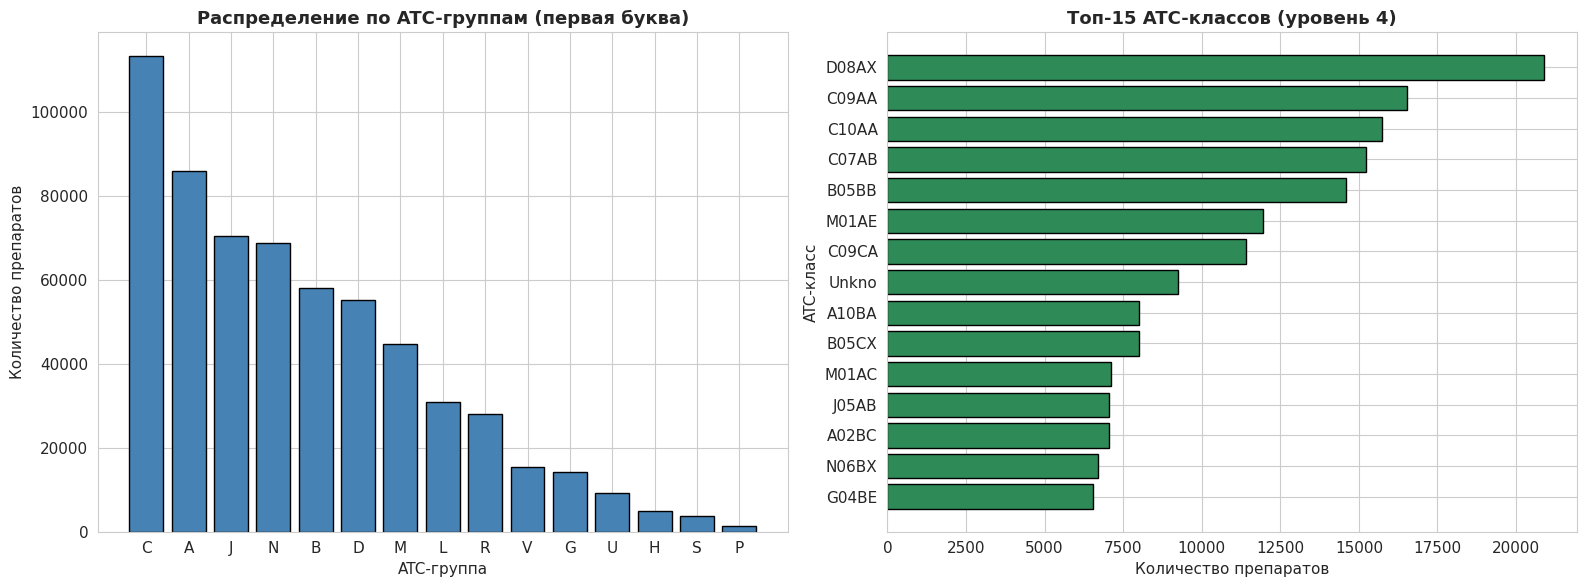


ИТОГ ОБРАБОТКИ code_atc
Было NULL:                9,240
Заполнено из mnn_reference: 0
Осталось Unknown:          9,240

Уникальных ATC-групп:      15
Уникальных ATC-классов:    721


In [11]:
# ============================================================
# ОБРАБОТКА code_atc 
# ============================================================

# --- Извлекаем первый валидный ATC-код ---
def extract_first_valid_atc(s):
    """
    Извлекает первый валидный ATC-код из строки.
    Примеры:
        'B05BB;B05BB01'         -> 'B05BB'
        '~;B05CX01;B05BA03'     -> 'B05CX01'
        'D08AX08'               -> 'D08AX08'
        '~'                     -> None
        None                    -> None
    """
    if pd.isna(s):
        return None
    
    # Разбиваем по ';'
    parts = str(s).split(';')
    
    # Ищем первый валидный код
    # Валидный = не пустой, не '~', начинается с буквы A-Z
    for part in parts:
        part = part.strip()
        if part and part != '~' and re.match(r'^[A-Z]', part):
            return part
    return None

df['atc_first'] = df['code_atc'].apply(extract_first_valid_atc)

print(f"Шаг 1: извлечён первый валидный код")
print(f"  NULL: {(df['atc_first'].isna()).sum():,}")
print(f"  Уникальных: {df['atc_first'].nunique():,}")

# --- Приводим к уровню 4 (5 символов) ---
def normalize_atc_level(s, level=5):
    """
    Приводит ATC-код к указанному уровню.
    Уровни:
        1 — буква (C)
        3 — 3 символа (C09)
        4 — 5 символов (C09AA)
        5 — 7 символов (C09AA02)
    """
    if pd.isna(s):
        return None
    
    s = str(s).strip().upper()
    
    if level == 1:
        return s[:1] if len(s) >= 1 else None
    elif level == 3:
        return s[:3] if len(s) >= 3 else s
    elif level == 4:
        return s[:5] if len(s) >= 5 else s
    elif level == 5:
        return s[:7] if len(s) >= 7 else s
    else:
        return s

df['atc_level4'] = df['atc_first'].apply(lambda x: normalize_atc_level(x, level=4))

print(f"\nШаг 2: приведён к уровню 4 (5 символов)")
print(f"  NULL: {(df['atc_level4'].isna()).sum():,}")
print(f"  Уникальных: {df['atc_level4'].nunique():,}")
print(f"\n  Топ-10:")
print(df['atc_level4'].value_counts().head(10))

# --- Заполняем NULL из mnn_reference ---
# Загружаем справочник МНН с ATC-кодами
query = """
SELECT smnn_code, code_atc
FROM raw_data.mnn_reference
WHERE code_atc IS NOT NULL AND code_atc != '~'
"""
mnn_atc = pd.read_sql(query, engine)
print(f"\nШаг 3: загружено {len(mnn_atc):,} ATC-кодов из mnn_reference")

# Создаём маппинг smnn_code -> atc
mnn_atc_map = dict(zip(mnn_atc['smnn_code'], mnn_atc['code_atc']))

# Применяем: где atc_level4 = NULL, берём из справочника
mask_null = df['atc_level4'].isna()
df.loc[mask_null, 'atc_from_mnn'] = df.loc[mask_null, 'smnn_code'].map(mnn_atc_map)

# Приводим к уровню 4
df['atc_from_mnn'] = df['atc_from_mnn'].apply(lambda x: normalize_atc_level(x, level=4) if pd.notna(x) else None)

# Заполняем
df['atc_filled'] = df['atc_level4'].fillna(df['atc_from_mnn'])

filled_count = mask_null.sum() - df['atc_filled'].isna().sum()
print(f"  Заполнено из mnn_reference: {filled_count:,}")
print(f"  Осталось NULL: {df['atc_filled'].isna().sum():,}")

# --- Заменяем оставшиеся NULL на 'Unknown' ---
df['atc_clean'] = df['atc_filled'].fillna('Unknown')

print(f"\nШаг 4: NULL заменены на 'Unknown'")
print(f"  Уникальных: {df['atc_clean'].nunique():,}")
print(f"  'Unknown': {(df['atc_clean'] == 'Unknown').sum():,}")

# --- Создаём производные признаки ---
df['atc_group'] = df['atc_clean'].str[:1]      # C, A, J...
df['atc_class'] = df['atc_clean'].str[:3]      # C09, A02...
df['atc_subclass'] = df['atc_clean'].str[:4]   # C09A, A02B...
df['atc_level4'] = df['atc_clean'].str[:5]     # C09AA, A02BC...

print(f"\nШаг 5: созданы производные признаки")
print(f"  atc_group: {df['atc_group'].nunique()} уникальных")
print(f"  atc_class: {df['atc_class'].nunique()} уникальных")
print(f"  atc_subclass: {df['atc_subclass'].nunique()} уникальных")
print(f"  atc_level4: {df['atc_level4'].nunique()} уникальных")

# --- ШАГ 6: Визуализация ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Распределение по ATC-группам (первая буква)
atc_group_counts = df['atc_group'].value_counts().head(15)
axes[0].bar(atc_group_counts.index, atc_group_counts.values, color='steelblue', edgecolor='black')
axes[0].set_title('Распределение по ATC-группам (первая буква)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('ATC-группа')
axes[0].set_ylabel('Количество препаратов')
axes[0].tick_params(axis='x', rotation=0)

# Распределение по ATC-классам (топ-15)
atc_class_counts = df['atc_level4'].value_counts().head(15)
axes[1].barh(atc_class_counts.index[::-1], atc_class_counts.values[::-1], color='seagreen', edgecolor='black')
axes[1].set_title('Топ-15 ATC-классов (уровень 4)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Количество препаратов')
axes[1].set_ylabel('ATC-класс')

plt.tight_layout()
# plt.savefig(f'{NOTEBOOK_DIR}/10_atc_clean.png', dpi=100, bbox_inches='tight')
plt.show()

# --- Финальная проверка ---
print("\n" + "=" * 60)
print("ИТОГ ОБРАБОТКИ code_atc")
print("=" * 60)
print(f"Было NULL:                9,240")
print(f"Заполнено из mnn_reference: {filled_count:,}")
print(f"Осталось Unknown:          {(df['atc_clean'] == 'Unknown').sum():,}")
print(f"\nУникальных ATC-групп:      {df['atc_group'].nunique()}")
print(f"Уникальных ATC-классов:    {df['atc_level4'].nunique()}")

Проверка: исходный code_atc сохранён?
code_atc — уникальных: 2,527
atc_clean — уникальных: 721

ПРИЗНАК is_combined_atc
is_combined_atc
0    472137
1    132212
Name: count, dtype: int64

Доля составных ATC: 21.88%

Распределение is_combined_atc по ATC-группам (топ-10):


,Составных,Всего,Доля
atc_group,,,
C,22002,113275,19.4
A,13087,85927,15.2
J,10843,70346,15.4
N,9654,68897,14.0
B,26480,58097,45.6
D,22570,55176,40.9
M,2501,44693,5.6
L,12317,30965,39.8
R,5838,28122,20.8


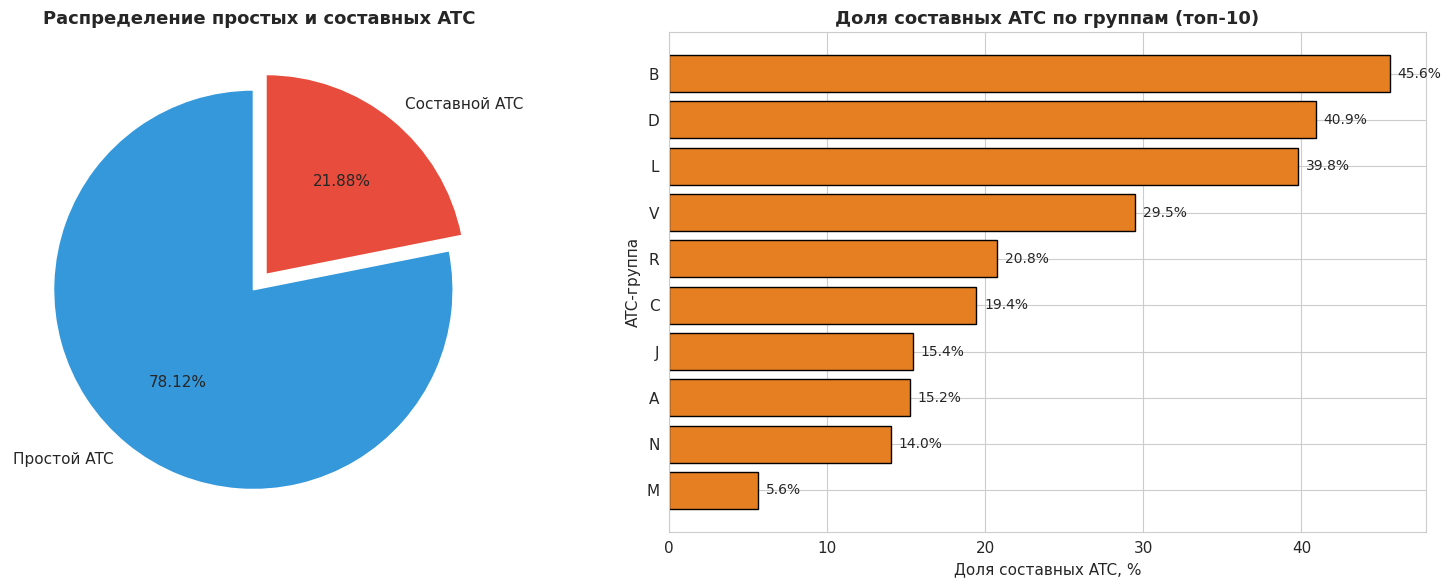

In [12]:
# ============================================================
# ДОБАВЛЯЕМ is_combined_atc
# ============================================================
# Составной ATC — это признак «комбинированный препарат».
# Один препарат может иметь несколько ATC-кодов,
# если он действует на несколько систем или является комбинированным.

# Проверяем, что исходный code_atc сохранён
print("Проверка: исходный code_atc сохранён?")
print(f"code_atc — уникальных: {df['code_atc'].nunique():,}")
print(f"atc_clean — уникальных: {df['atc_clean'].nunique():,}")

# --- Создаём признак is_combined_atc ---
# 1 — был составной код (с ';')
# 0 — был простой код или NULL
df['is_combined_atc'] = df['code_atc'].str.contains(';', na=False).astype(int)

print("\n" + "=" * 60)
print("ПРИЗНАК is_combined_atc")
print("=" * 60)
print(df['is_combined_atc'].value_counts())
print(f"\nДоля составных ATC: {df['is_combined_atc'].mean() * 100:.2f}%")

# --- Проверяем связь: is_combined_atc vs atc_group ---
print("\nРаспределение is_combined_atc по ATC-группам (топ-10):")
combined_by_group = df.groupby('atc_group')['is_combined_atc'].agg(['sum', 'count', 'mean'])
combined_by_group.columns = ['Составных', 'Всего', 'Доля']
combined_by_group['Доля'] = (combined_by_group['Доля'] * 100).round(1)
combined_by_group = combined_by_group.sort_values('Всего', ascending=False).head(10)
display(combined_by_group)

# --- Визуализация ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Слева: общее распределение
combined_counts = df['is_combined_atc'].value_counts()
labels = ['Простой ATC', 'Составной ATC']
colors = ['#3498db', '#e74c3c']
axes[0].pie(combined_counts.values, labels=labels, autopct='%1.2f%%',
            colors=colors, startangle=90, explode=(0.05, 0.05))
axes[0].set_title('Распределение простых и составных ATC',
                  fontsize=13, fontweight='bold')

# Справа: доля составных по ATC-группам
top_groups = df['atc_group'].value_counts().head(10).index
combined_share = df[df['atc_group'].isin(top_groups)].groupby('atc_group')['is_combined_atc'].mean() * 100
combined_share = combined_share.sort_values(ascending=True)

axes[1].barh(combined_share.index, combined_share.values, color='#e67e22', edgecolor='black')
axes[1].set_title('Доля составных ATC по группам (топ-10)',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Доля составных ATC, %')
axes[1].set_ylabel('ATC-группа')

for i, v in enumerate(combined_share.values):
    axes[1].text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=10)

plt.tight_layout()
# plt.savefig(f'{NOTEBOOK_DIR}/11_combined_atc.png', dpi=100, bbox_inches='tight')
plt.show()


In [13]:
# Создаём явную копию code_atc с суффиксом _raw для аудита (если модель покажет странный прогноз).
df['code_atc_raw'] = df['code_atc'].copy()

print("ПРИЗНАК code_atc_raw")
print(f"Уникальных значений: {df['code_atc_raw'].nunique():,}")
print(f"NULL: {df['code_atc_raw'].isna().sum():,}")
print(f"Примеры:")
print(df[['code_atc_raw', 'atc_clean', 'is_combined_atc']].head(10))

ПРИЗНАК code_atc_raw
Уникальных значений: 2,527
NULL: 9,240
Примеры:
  code_atc_raw atc_clean  is_combined_atc
0         None   Unknown                0
1      A06AB58     A06AB                0
2      A06AB58     A06AB                0
3      G03BA03     G03BA                0
4      G03BA03     G03BA                0
5      G03GA05     G03GA                0
6      G03GA05     G03GA                0
7      G03GA05     G03GA                0
8      N05AX15     N05AX                0
9      N05AX15     N05AX                0


In [14]:
# ============================================================
# УДАЛЯЕМ ПРОМЕЖУТОЧНЫЕ КОЛОНКИ
# ============================================================
intermediate_cols = [
    'atc_first',           
    'atc_from_mnn',        
    'atc_filled',          
    'atc_has_semicolon',   
    'atc_parts_count',     
    'atc_has_tilde',     
]

cols_to_drop = [c for c in intermediate_cols if c in df.columns]
df = df.drop(columns=cols_to_drop)

print("УДАЛЕНЫ ПРОМЕЖУТОЧНЫЕ КОЛОНКИ")
print(f"Удалено: {cols_to_drop}")

# Финальный список колонок по ATC
atc_cols = [
    'code_atc_raw',      # исходный (для аудита)
    'atc_clean',         # финальный ATC (уровень 4)
    'atc_group',         # C, A, J...
    'atc_class',         # C09, A02...
    'atc_subclass',      # C09A, A02B...
    'atc_level4',        # C09AA, A02BC...
    'is_combined_atc',   # 0/1
]
print(f"\nФинальные колонки по ATC: {atc_cols}")
print(f"\nПримеры:")
display(df[atc_cols].head(10))

УДАЛЕНЫ ПРОМЕЖУТОЧНЫЕ КОЛОНКИ
Удалено: ['atc_first', 'atc_from_mnn', 'atc_filled', 'atc_has_semicolon', 'atc_parts_count', 'atc_has_tilde']

Финальные колонки по ATC: ['code_atc_raw', 'atc_clean', 'atc_group', 'atc_class', 'atc_subclass', 'atc_level4', 'is_combined_atc']

Примеры:


,code_atc_raw,atc_clean,atc_group,atc_class,atc_subclass,atc_level4,is_combined_atc
0,None,Unknown,U,Unk,Unkn,Unkno,0
1,A06AB58,A06AB,A,A06,A06A,A06AB,0
2,A06AB58,A06AB,A,A06,A06A,A06AB,0
3,G03BA03,G03BA,G,G03,G03B,G03BA,0
4,G03BA03,G03BA,G,G03,G03B,G03BA,0
5,G03GA05,G03GA,G,G03,G03G,G03GA,0
6,G03GA05,G03GA,G,G03,G03G,G03GA,0
7,G03GA05,G03GA,G,G03,G03G,G03GA,0
8,N05AX15,N05AX,N,N05,N05A,N05AX,0
9,N05AX15,N05AX,N,N05,N05A,N05AX,0


In [15]:
# ============================================================
# ФИНАЛЬНАЯ ПРОВЕРКА code_atc
# ============================================================
print("ИТОГ ОБРАБОТКИ code_atc")
print(f"Всего препаратов:            {len(df):,}")
print(f"Уникальных ATC-групп:        {df['atc_group'].nunique()}")
print(f"Уникальных ATC-классов:      {df['atc_class'].nunique()}")
print(f"Уникальных ATC-подклассов:   {df['atc_subclass'].nunique()}")
print(f"Уникальных ATC-уровень 4:    {df['atc_level4'].nunique()}")
print(f"Составных ATC:               {df['is_combined_atc'].sum():,} ({df['is_combined_atc'].mean()*100:.2f}%)")
print(f"Unknown ATC:                 {(df['atc_clean'] == 'Unknown').sum():,}")
print(f"\nNULL в финальных колонках:")
for col in atc_cols:
    nulls = df[col].isna().sum()
    print(f"  {col}: {nulls:,}")

ИТОГ ОБРАБОТКИ code_atc
Всего препаратов:            604,349
Уникальных ATC-групп:        15
Уникальных ATC-классов:      93
Уникальных ATC-подклассов:   263
Уникальных ATC-уровень 4:    721
Составных ATC:               132,212 (21.88%)
Unknown ATC:                 9,240

NULL в финальных колонках:
  code_atc_raw: 9,240
  atc_clean: 0
  atc_group: 0
  atc_class: 0
  atc_subclass: 0
  atc_level4: 0
  is_combined_atc: 0


## okei_code

In [16]:
# ============================================================
# ДИАГНОСТИКА okei_code
# ============================================================

# Загружаем unit_reference
units = pd.read_sql("SELECT * FROM raw_data.unit_reference", engine)
print("UNIT_REFERENCE (все записи)")
display(units)

# Смотрим, какие okei_code встречаются в drug_products
query = """
SELECT 
    okei_code,
    COUNT(*) AS count
FROM raw_data.drug_products
WHERE actual = TRUE
GROUP BY okei_code
ORDER BY count DESC
"""
okei_usage = pd.read_sql(query, engine)
print("OKEI_CODE В DRUG_PRODUCTS (актуальные)")
display(okei_usage)

# Смотрим, какие okei_code НЕ найдены в unit_reference
query = """
SELECT DISTINCT
    dp.okei_code,
    COUNT(*) OVER (PARTITION BY dp.okei_code) AS count
FROM raw_data.drug_products dp
LEFT JOIN raw_data.unit_reference ur ON dp.okei_code = ur.okei_code
WHERE ur.okei_code IS NULL
  AND dp.actual = TRUE
ORDER BY count DESC
"""
orphans_detail = pd.read_sql(query, engine)
print("СИРОТЫ (okei_code без unit_reference) — в актуальных")
display(orphans_detail)

# Смотрим примеры препаратов с этими кодами
for code in orphans_detail['okei_code'].tolist():
    print(f"\n--- Примеры препаратов с okei_code = {code} ---")
    query = f"""
    SELECT name_trade, standard_inn, okei_code
    FROM raw_data.drug_products
    WHERE okei_code = {code} AND actual = TRUE
    LIMIT 5
    """
    examples = pd.read_sql(query, engine)
    display(examples)

UNIT_REFERENCE (все записи)


,id,okei_code,id_original,name_unit,file_name,created_at,updated_at
0,1,163,1,г действующего вещества,unit_reference.csv,2026-09-09 18:43:18.063256,2026-09-09 18:43:18.063256
1,2,163,2,г лекарственной формы,unit_reference.csv,2026-09-09 18:43:18.063256,2026-09-09 18:43:18.063256
2,3,639,3,доз(а),unit_reference.csv,2026-09-09 18:43:18.063256,2026-09-09 18:43:18.063256
3,4,9920,4,ЕД,unit_reference.csv,2026-09-09 18:43:18.063256,2026-09-09 18:43:18.063256
4,5,166,5,кг,unit_reference.csv,2026-09-09 18:43:18.063256,2026-09-09 18:43:18.063256
5,6,112,6,л,unit_reference.csv,2026-09-09 18:43:18.063256,2026-09-09 18:43:18.063256
6,7,113,7,м3,unit_reference.csv,2026-09-09 18:43:18.063256,2026-09-09 18:43:18.063256
7,8,307,8,МБк,unit_reference.csv,2026-09-09 18:43:18.063256,2026-09-09 18:43:18.063256
8,9,161,9,мг действующего вещества,unit_reference.csv,2026-09-09 18:43:18.063256,2026-09-09 18:43:18.063256
9,10,161,10,мг лекарственной формы,unit_reference.csv,2026-09-09 18:43:18.063256,2026-09-09 18:43:18.063256


OKEI_CODE В DRUG_PRODUCTS (актуальные)


,okei_code,count
0,796,364070
1,111,176732
2,163,42110
3,161,12671
4,639,4058
5,113,1979
6,9910,708
7,876,512
8,9920,476
9,9912,321


СИРОТЫ (okei_code без unit_reference) — в актуальных


,okei_code,count


Зачем ref_data.unit_canonical
Проблема: в raw_data.unit_reference (ЕСКЛП) один okei_code имеет много name_unit (например, 796 → 31 вариация: «шт.», «шт. (таблетка)», «шт. (упаковка)»...). Для ML это плохо: One-Hot даст 46+ разреженных колонок, модель не поймёт, что «таблетка» и «капсула» — одно и то же.

Решение: создаём чистый справочник ref_data.unit_canonical, где один okei_code = одна строка с каноническим названием (etalon_name) и типом единицы (unit_type: count/volume/mass/activity/dose/radioactivity). 14 записей вместо 46, 6 категорий вместо 46 — модель выучит осмысленный паттерн «таблетки vs растворы», а не шум.

In [17]:
# ============================================================
# ОБРАБОТКА okei_code
# ============================================================

# --- 1. Загружаем справочник ---
unit_ref = pd.read_sql("""
    SELECT okei_code, etalon_name, unit_type
    FROM ref_data.unit_canon
""", engine)

print(f"✅ Загружено единиц: {len(unit_ref):,}")
display(unit_ref)

# --- 2. Создаём маппинги ---
unit_name_map = dict(zip(unit_ref['okei_code'], unit_ref['etalon_name']))
unit_type_map = dict(zip(unit_ref['okei_code'], unit_ref['unit_type']))

# --- 3. Применяем к df ---
df['okei_code_str'] = df['okei_code'].astype(str)
df['unit_name'] = df['okei_code_str'].map(unit_name_map)
df['unit_type'] = df['okei_code_str'].map(unit_type_map)

# --- 4. Проверяем, что все нашли ---
missing = df['unit_name'].isna().sum()
if missing > 0:
    print(f"\n⚠️  Не найдено в справочнике: {missing:,} записей")
    print("Уникальные ненайденные okei_code:")
    print(df[df['unit_name'].isna()]['okei_code'].value_counts())
else:
    print("\n✅ Все okei_code найдены в справочнике!")

# --- 5. Смотрим распределение ---
print("РАСПРЕДЕЛЕНИЕ ПО unit_name")
print(df['unit_name'].value_counts())

print("РАСПРЕДЕЛЕНИЕ ПО unit_type")
print(df['unit_type'].value_counts())

✅ Загружено единиц: 14


,okei_code,etalon_name,unit_type
0,796,шт.,count
1,111,мл,volume
2,163,г,mass
3,161,мг,mass
4,639,доза,dose
5,113,м3,volume
6,9910,МЕ,activity
7,876,млн.ЕД,activity
8,9920,ЕД,activity
9,9912,млн.МЕ,activity



✅ Все okei_code найдены в справочнике!
РАСПРЕДЕЛЕНИЕ ПО unit_name
unit_name
шт.       364070
мл        176732
г          42110
мг         12671
доза        4058
м3          1979
МЕ           708
млн.ЕД       512
ЕД           476
млн.МЕ       321
МБк          311
л            262
мкг          117
кг            22
Name: count, dtype: int64
РАСПРЕДЕЛЕНИЕ ПО unit_type
unit_type
count            364070
volume           178973
mass              54920
dose               4058
activity           2017
radioactivity       311
Name: count, dtype: int64


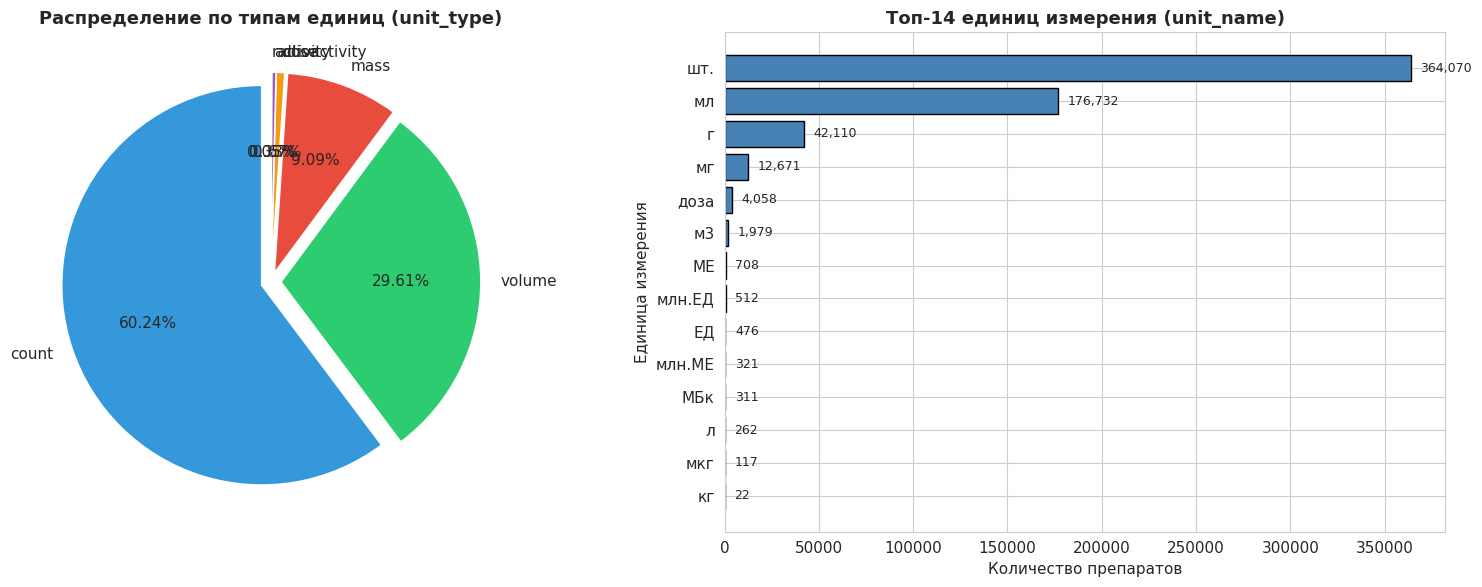

In [18]:
# ============================================================
# ВИЗУАЛИЗАЦИЯ unit_type
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Слева: распределение по unit_type
unit_type_counts = df['unit_type'].value_counts()
colors = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6', '#1abc9c']
axes[0].pie(unit_type_counts.values, 
            labels=unit_type_counts.index,
            autopct='%1.2f%%',
            colors=colors[:len(unit_type_counts)],
            startangle=90,
            explode=[0.05] * len(unit_type_counts))
axes[0].set_title('Распределение по типам единиц (unit_type)',
                  fontsize=13, fontweight='bold')

# Справа: топ-14 unit_name
unit_name_counts = df['unit_name'].value_counts().head(14)
axes[1].barh(unit_name_counts.index[::-1], unit_name_counts.values[::-1],
             color='steelblue', edgecolor='black')
axes[1].set_title('Топ-14 единиц измерения (unit_name)',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Количество препаратов')
axes[1].set_ylabel('Единица измерения')

for i, v in enumerate(unit_name_counts.values[::-1]):
    axes[1].text(v + 5000, i, f'{v:,}', va='center', fontsize=9)

plt.tight_layout()
# plt.savefig(f'{NOTEBOOK_DIR}/12_unit_types.png', dpi=100, bbox_inches='tight')
plt.show()

In [19]:
# ============================================================
# ИТОГ ОБРАБОТКИ okei_code
# ============================================================
print("ИТОГ ОБРАБОТКИ okei_code")
print(f"Всего препаратов: {len(df):,}")
print(f"Уникальных okei_code: {df['okei_code'].nunique()}")
print(f"Уникальных unit_name: {df['unit_name'].nunique()}")
print(f"Уникальных unit_type: {df['unit_type'].nunique()}")
print(f"\nNULL в финальных колонках:")
print(f"  unit_name: {df['unit_name'].isna().sum():,}")
print(f"  unit_type: {df['unit_type'].isna().sum():,}")

ИТОГ ОБРАБОТКИ okei_code
Всего препаратов: 604,349
Уникальных okei_code: 14
Уникальных unit_name: 14
Уникальных unit_type: 6

NULL в финальных колонках:
  unit_name: 0
  unit_type: 0


## country

In [20]:
# ============================================================
# ДИАГНОСТИКА country
# ============================================================

print("COUNTRY — ОБЩАЯ СТАТИСТИКА")
print(f"NULL: {df['country'].isna().sum():,}")
print(f"Пустых строк: {(df['country'] == '').sum():,}")
print(f"Уникальных: {df['country'].nunique():,}")

# --- Распределение ---
print("РАСПРЕДЕЛЕНИЕ ПО СТРАНАМ (топ-20)")
country_counts = df['country'].value_counts()
print(country_counts.head(20))

# --- Проверка омоглифов ---
print("ПРОВЕРКА ОМОГЛИФОВ")
latin_in_country = df[df['country'].str.contains(r'[A-Za-z]', na=False, regex=True)]
print(f"Стран с латиницей: {latin_in_country['country'].nunique()}")
if len(latin_in_country) > 0:
    print(latin_in_country['country'].value_counts().head(20))

# --- Проверка дубликатов-вариаций ---
print("ПРОВЕРКА ВАРИАЦИЙ НАПИСАНИЯ")
# Ищем страны, которые могут быть вариантами одной
# Например, "СОЕДИНЕННЫЕ ШТАТЫ" vs "США"
all_countries = sorted(df['country'].dropna().unique())
print(f"Все {len(all_countries)} стран:")
for c in all_countries:
    count = country_counts.get(c, 0)
    print(f"  {c} ({count:,})")

COUNTRY — ОБЩАЯ СТАТИСТИКА
NULL: 0
Пустых строк: 0
Уникальных: 77
РАСПРЕДЕЛЕНИЕ ПО СТРАНАМ (топ-20)
country
РОССИЯ                     528431
ИНДИЯ                       18632
ГЕРМАНИЯ                     7825
СЛОВЕНИЯ                     6142
ФРАНЦИЯ                      3808
БЕЛАРУСЬ                     3711
ИТАЛИЯ                       3371
ИСПАНИЯ                      2579
ВЕНГРИЯ                      2257
ПОЛЬША                       2038
СОЕДИНЕННЫЕ ШТАТЫ            1533
ШВЕЙЦАРИЯ                    1468
ИРЛАНДИЯ                     1404
ТУРЦИЯ                       1396
АВСТРИЯ                      1360
СОЕДИНЕННОЕ КОРОЛЕВСТВО      1272
КИТАЙ                        1131
КАНАДА                       1113
БОЛГАРИЯ                      994
КАЗАХСТАН                     946
Name: count, dtype: int64
ПРОВЕРКА ОМОГЛИФОВ
Стран с латиницей: 0
ПРОВЕРКА ВАРИАЦИЙ НАПИСАНИЯ
Все 77 стран:
  АВСТРАЛИЯ (47)
  АВСТРИЯ (1,360)
  АРГЕНТИНА (292)
  АРМЕНИЯ (113)
  БЕЛАРУСЬ (3,711)
  БЕЛЬГИЯ (732)


In [21]:
# ============================================================
# ОБРАБОТКА country
# ============================================================

# --- 1. Загружаем справочник ---
country_ref = pd.read_sql("""
    SELECT 
        country_name, 
        country_group, 
        is_russian
    FROM ref_data.country_groups
""", engine)

print(f"✅ Загружено стран в справочнике: {len(country_ref):,}")

# --- 2. Создаём маппинги ---
country_group_map = dict(zip(country_ref['country_name'], country_ref['country_group']))
is_russian_map = dict(zip(country_ref['country_name'], country_ref['is_russian']))

# --- 3. Применяем ---
df['country_group'] = df['country'].map(country_group_map)
df['is_russian'] = df['country'].map(is_russian_map)

# --- 4. Обрабатываем ненайденные ---
missing_mask = df['country_group'].isna()
missing_count = missing_mask.sum()

if missing_count > 0:
    print(f"\n⚠️  Не найдено в справочнике: {missing_count:,} записей")
    print("Уникальные ненайденные страны:")
    missing_countries = df[missing_mask]['country'].value_counts()
    print(missing_countries)
    
    # Заполняем как Other
    df.loc[missing_mask, 'country_group'] = 'Other'
    df.loc[missing_mask, 'is_russian'] = False
else:
    print("\n✅ Все страны найдены в справочнике!")

# --- 5. Проверяем ---
print("\nРАСПРЕДЕЛЕНИЕ ПО country_group")
print(df['country_group'].value_counts())

print("\nРАСПРЕДЕЛЕНИЕ ПО is_russian")
print(df['is_russian'].value_counts())

✅ Загружено стран в справочнике: 86

✅ Все страны найдены в справочнике!

РАСПРЕДЕЛЕНИЕ ПО country_group
country_group
Russia      528431
Europe       43454
Asia         22958
CIS           5340
Americas      4054
Africa          65
Other           47
Name: count, dtype: int64

РАСПРЕДЕЛЕНИЕ ПО is_russian
is_russian
True     528431
False     75918
Name: count, dtype: int64


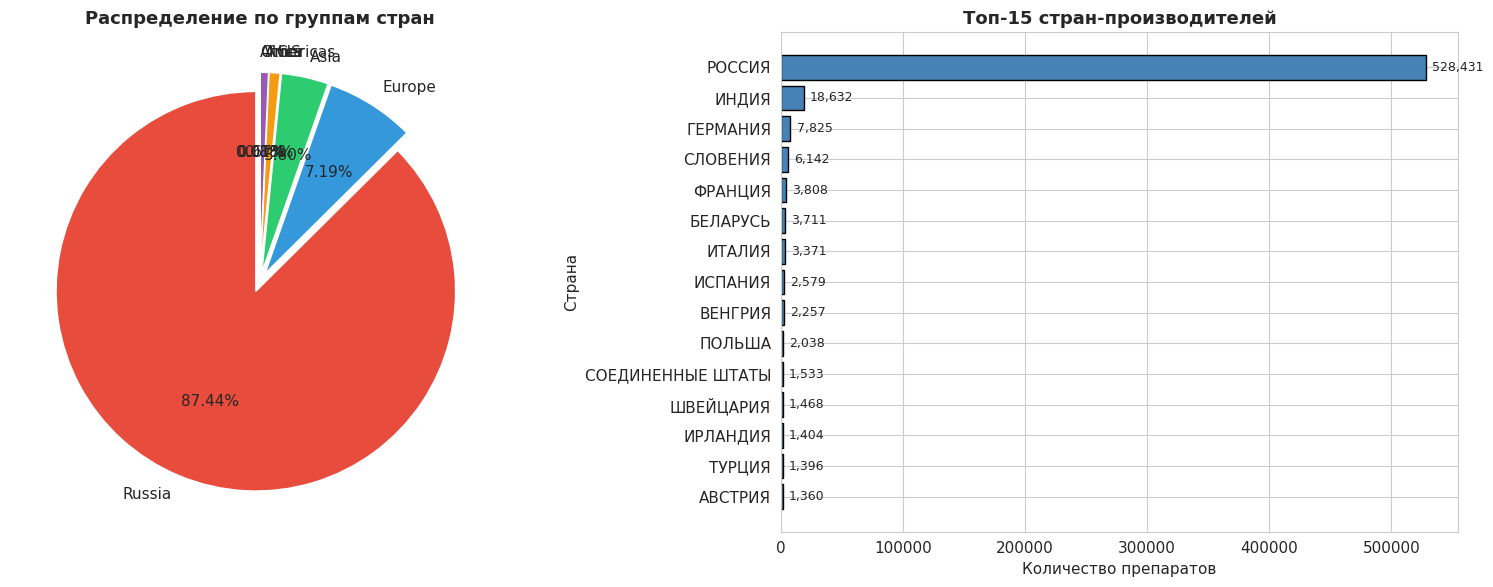

In [22]:
# ============================================================
# ВИЗУАЛИЗАЦИЯ country
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Слева: распределение по группам
group_counts = df['country_group'].value_counts()
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c', '#95a5a6']
axes[0].pie(group_counts.values,
            labels=group_counts.index,
            autopct='%1.2f%%',
            colors=colors[:len(group_counts)],
            startangle=90,
            explode=[0.05] * len(group_counts))
axes[0].set_title('Распределение по группам стран',
                  fontsize=13, fontweight='bold')

# Справа: топ-15 стран
top_countries = df['country'].value_counts().head(15)
axes[1].barh(top_countries.index[::-1], top_countries.values[::-1],
             color='steelblue', edgecolor='black')
axes[1].set_title('Топ-15 стран-производителей',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Количество препаратов')
axes[1].set_ylabel('Страна')

for i, v in enumerate(top_countries.values[::-1]):
    axes[1].text(v + 5000, i, f'{v:,}', va='center', fontsize=9)

plt.tight_layout()
# plt.savefig(f'{NOTEBOOK_DIR}/13_country_groups.png', dpi=100, bbox_inches='tight')
plt.show()

In [23]:
print("ИТОГ ОБРАБОТКИ country")
print(f"Всего препаратов: {len(df):,}")
print(f"Уникальных стран: {df['country'].nunique()}")
print(f"Уникальных групп: {df['country_group'].nunique()}")
print(f"\nNULL в финальных колонках:")
print(f"country_group: {df['country_group'].isna().sum():,}")
print(f"is_russian: {df['is_russian'].isna().sum():,}")

ИТОГ ОБРАБОТКИ country
Всего препаратов: 604,349
Уникальных стран: 77
Уникальных групп: 7

NULL в финальных колонках:
country_group: 0
is_russian: 0


## date_registration

DATE_REGISTRATION — ОБЩАЯ СТАТИСТИКА
Тип: datetime64[ns]
NULL/NaT: 0

Min: 1969-06-18 00:00:00
Max: 2026-08-17 00:00:00

Сегодня: 2026-11-28 13:35:14.031307
Дат < 1950:      0
Дат > сегодня:   0
РАСПРЕДЕЛЕНИЕ ПО ГОДАМ (топ-20)
date_registration
2026    20724
2025    74217
2024    81755
2023    59109
2022    39170
2021    39534
2020    14373
2019    20677
2018    25369
2017    10915
2016    16018
2015    15296
2014    14598
2013     8850
2012    18502
2011    34934
2010    28187
2009    28119
2008    39771
2007    13691
Name: count, dtype: int64
РАСПРЕДЕЛЕНИЕ ПО МЕСЯЦАМ
date_registration
1     36603
2     56708
3     53467
4     44984
5     46464
6     47004
7     51602
8     54106
9     47291
10    51779
11    48542
12    65799
Name: count, dtype: int64
РАСПРЕДЕЛЕНИЕ ПО КВАРТАЛАМ
date_registration
1    146778
2    138452
3    152999
4    166120
Name: count, dtype: int64


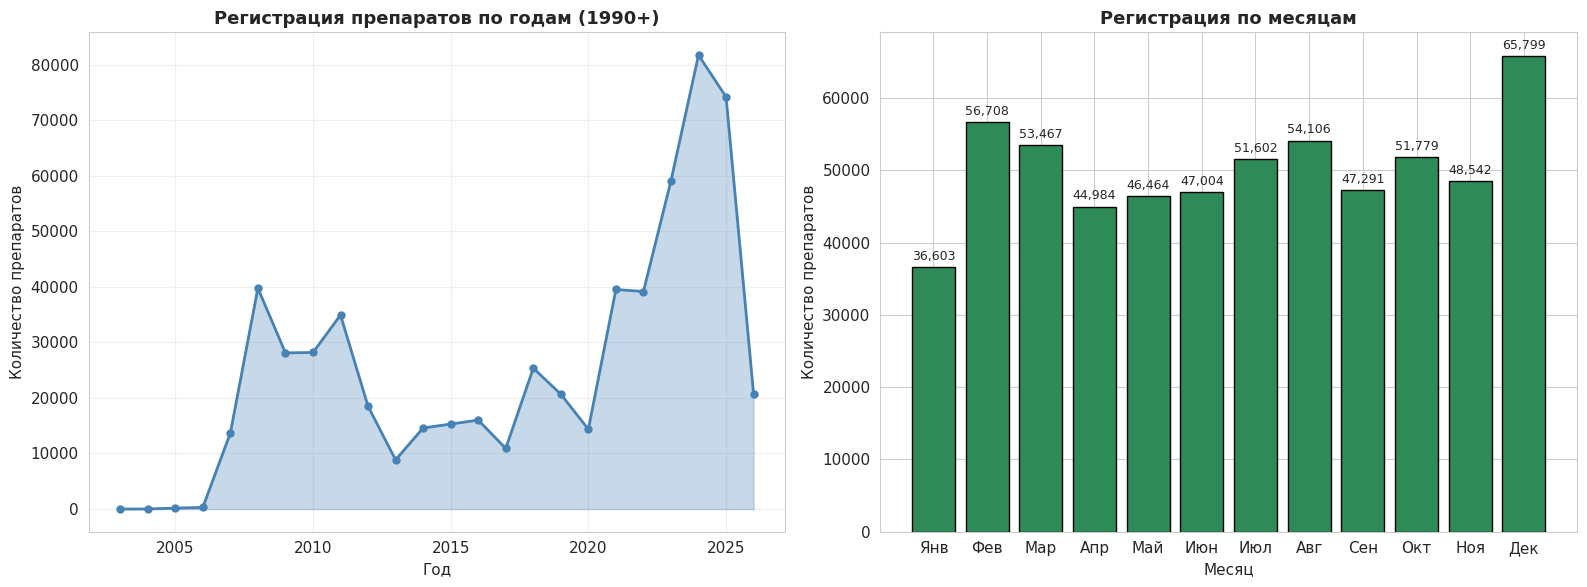

In [24]:
# ============================================================
# ДИАГНОСТИКА date_registration
# ============================================================

print("DATE_REGISTRATION — ОБЩАЯ СТАТИСТИКА")

# --- 1. Приводим к datetime ---
df['date_registration'] = pd.to_datetime(df['date_registration'], errors='coerce')

print(f"Тип: {df['date_registration'].dtype}")
print(f"NULL/NaT: {df['date_registration'].isna().sum():,}")

# --- 2. Диапазон дат ---
print(f"\nMin: {df['date_registration'].min()}")
print(f"Max: {df['date_registration'].max()}")

# --- 3. Аномалии ---
today = pd.Timestamp.today()
print(f"\nСегодня: {today}")

ancient = df[df['date_registration'] < '1950-01-01']
future = df[df['date_registration'] > today]

print(f"Дат < 1950:      {len(ancient):,}")
print(f"Дат > сегодня:   {len(future):,}")

if len(ancient) > 0:
    print(f"\nПримеры древних дат:")
    display(ancient[['name_trade', 'date_registration']].head(10))

if len(future) > 0:
    print(f"\nПримеры будущих дат:")
    display(future[['name_trade', 'date_registration']].head(10))

# --- 4. Распределение по годам ---
print("РАСПРЕДЕЛЕНИЕ ПО ГОДАМ (топ-20)")
year_counts = df['date_registration'].dt.year.value_counts().sort_index(ascending=False)
print(year_counts.head(20))

# --- 5. Распределение по месяцам ---
print("РАСПРЕДЕЛЕНИЕ ПО МЕСЯЦАМ")
month_counts = df['date_registration'].dt.month.value_counts().sort_index()
print(month_counts)

# --- 6. Распределение по кварталам ---
print("РАСПРЕДЕЛЕНИЕ ПО КВАРТАЛАМ")
quarter_counts = df['date_registration'].dt.quarter.value_counts().sort_index()
print(quarter_counts)

# --- 7. Визуализация распределения по годам ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Слева: по годам
year_series = df['date_registration'].dt.year.value_counts().sort_index()
year_series = year_series[year_series.index >= 1990]  # фильтруем старые
axes[0].plot(year_series.index, year_series.values, marker='o',
             linewidth=2, markersize=5, color='steelblue')
axes[0].fill_between(year_series.index, year_series.values, alpha=0.3, color='steelblue')
axes[0].set_title('Регистрация препаратов по годам (1990+)',
                  fontsize=13, fontweight='bold')
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Количество препаратов')
axes[0].grid(True, alpha=0.3)

# Справа: по месяцам
month_labels = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
                'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']
month_counts = df['date_registration'].dt.month.value_counts().sort_index()
axes[1].bar(month_labels, month_counts.values, color='seagreen', edgecolor='black')
axes[1].set_title('Регистрация по месяцам',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Количество препаратов')

for i, v in enumerate(month_counts.values):
    axes[1].text(i, v + 1000, f'{v:,}', ha='center', fontsize=9)

plt.tight_layout()
# plt.savefig(f'{NOTEBOOK_DIR}/14_date_registration.png', dpi=100, bbox_inches='tight')
plt.show()

Обработка аномалий
Дат < 1950:    0
Дат > сегодня: 0

После очистки:
NaT: 0
Min: 1969-06-18 00:00:00
Max: 2026-08-17 00:00:00

ШАГ 2: Извлекаем компоненты даты

Созданные признаки:
reg_year: 27 уникальных
reg_month: 12 уникальных
reg_quarter: 4 уникальных
reg_weekday: 7 уникальных
years_since_registration:  min=0.28, max=57.45, mean=8.04

Обработка NaT в производных
NaT в reg_year: 0 (0.00%)

NaT оставлены как есть. Решение о заполнении — на этапе ML.

Визуализация


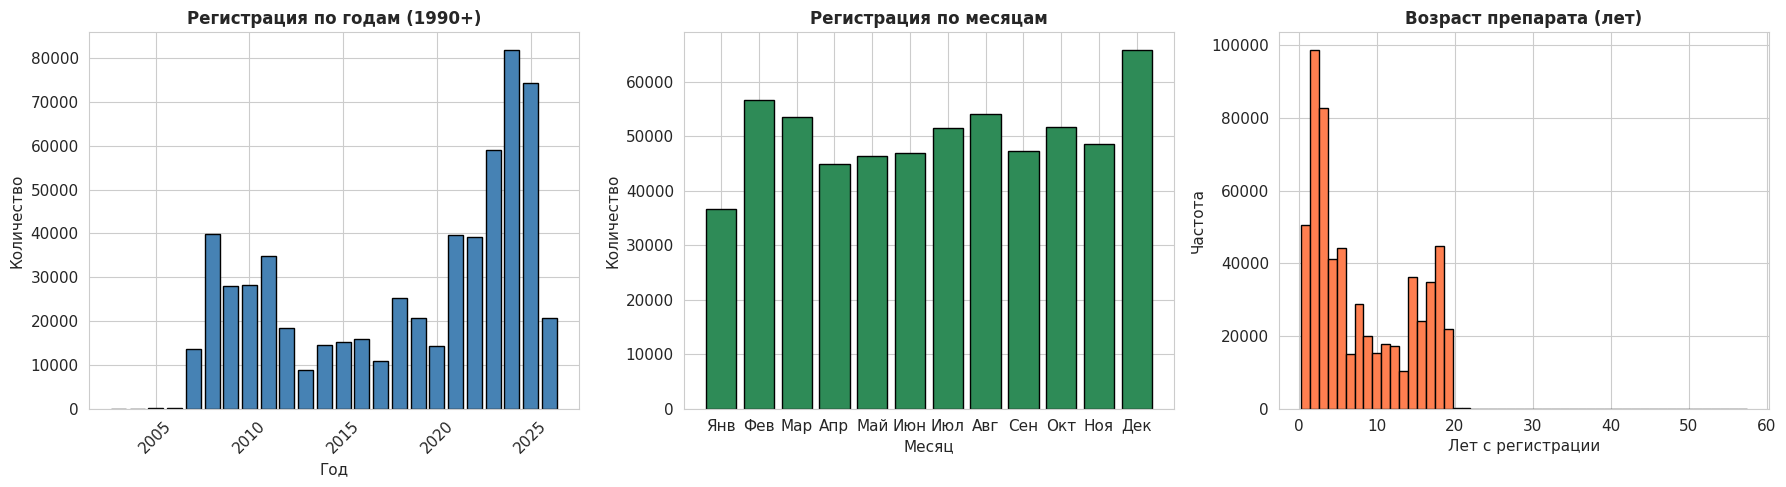

ИТОГ ОБРАБОТКИ date_registration
Всего препаратов: 604,349
NaT в date_registration: 0
Диапазон лет: 1969 – 2026
Средний возраст препарата: 8.0 лет
Медианный возраст: 5.5 лет

Созданные признаки:
reg_year
reg_month
reg_quarter
reg_weekday
years_since_registration


In [25]:
# ============================================================
# ОБРАБОТКА date_registration
# ============================================================
print("Обработка аномалий")

# --- Приводим к datetime ---
df['date_registration'] = pd.to_datetime(df['date_registration'], errors='coerce')

# --- Считаем аномалии ---
today = pd.Timestamp.today()
ancient_mask = df['date_registration'] < '1950-01-01'
future_mask = df['date_registration'] > today

print(f"Дат < 1950:    {ancient_mask.sum():,}")
print(f"Дат > сегодня: {future_mask.sum():,}")

# --- Заменяем на NaT ---
df.loc[ancient_mask, 'date_registration'] = pd.NaT
df.loc[future_mask, 'date_registration'] = pd.NaT

print(f"\nПосле очистки:")
print(f"NaT: {df['date_registration'].isna().sum():,}")
print(f"Min: {df['date_registration'].min()}")
print(f"Max: {df['date_registration'].max()}")

print("\nШАГ 2: Извлекаем компоненты даты")

# --- Год ---
df['reg_year'] = df['date_registration'].dt.year

# --- Месяц ---
df['reg_month'] = df['date_registration'].dt.month

# --- Квартал ---
df['reg_quarter'] = df['date_registration'].dt.quarter

# --- День недели (0=пн, 6=вс) ---
df['reg_weekday'] = df['date_registration'].dt.weekday

# --- Возраст препарата (лет) ---
df['years_since_registration'] = (today - df['date_registration']).dt.days / 365.25

print("\nСозданные признаки:")
print(f"reg_year: {df['reg_year'].nunique()} уникальных")
print(f"reg_month: {df['reg_month'].nunique()} уникальных")
print(f"reg_quarter: {df['reg_quarter'].nunique()} уникальных")
print(f"reg_weekday: {df['reg_weekday'].nunique()} уникальных")
print(f"years_since_registration:  min={df['years_since_registration'].min():.2f}, "
      f"max={df['years_since_registration'].max():.2f}, "
      f"mean={df['years_since_registration'].mean():.2f}")

print("\nОбработка NaT в производных")

# --- Проверяем, сколько NaT ---
nat_count = df['reg_year'].isna().sum()
print(f"NaT в reg_year: {nat_count:,} ({nat_count / len(df) * 100:.2f}%)")
print("\nNaT оставлены как есть. Решение о заполнении — на этапе ML.")

print("\nВизуализация")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- По годам ---
year_series = df['reg_year'].value_counts().sort_index()
year_series = year_series[year_series.index >= 1990]
axes[0].bar(year_series.index, year_series.values, color='steelblue', edgecolor='black')
axes[0].set_title('Регистрация по годам (1990+)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Количество')
axes[0].tick_params(axis='x', rotation=45)

# --- По месяцам ---
month_labels = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
                'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']
month_counts = df['reg_month'].value_counts().sort_index()
axes[1].bar(month_labels, month_counts.values, color='seagreen', edgecolor='black')
axes[1].set_title('Регистрация по месяцам', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Количество')

# --- Возраст препарата ---
axes[2].hist(df['years_since_registration'].dropna(), bins=50,
             color='coral', edgecolor='black')
axes[2].set_title('Возраст препарата (лет)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Лет с регистрации')
axes[2].set_ylabel('Частота')

plt.tight_layout()
# plt.savefig(f'{NOTEBOOK_DIR}/15_date_features.png', dpi=100, bbox_inches='tight')
plt.show()


print("ИТОГ ОБРАБОТКИ date_registration")
print(f"Всего препаратов: {len(df):,}")
print(f"NaT в date_registration: {df['date_registration'].isna().sum():,}")
print(f"Диапазон лет: {df['reg_year'].min():.0f} – {df['reg_year'].max():.0f}")
print(f"Средний возраст препарата: {df['years_since_registration'].mean():.1f} лет")
print(f"Медианный возраст: {df['years_since_registration'].median():.1f} лет")
print(f"\nСозданные признаки:")
print(f"reg_year")
print(f"reg_month")
print(f"reg_quarter")
print(f"reg_weekday")
print(f"years_since_registration")

# Агрегация данных по smnn_code

In [26]:
# Добавляем поле норм наименований 
df['name_producer_normalized'] = df['name_producer'].map(mapping)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 604349 entries, 0 to 604348
Data columns (total 36 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   id_original               604349 non-null  int64         
 1   name_trade                604349 non-null  object        
 2   standard_inn              604349 non-null  object        
 3   smnn_code                 604349 non-null  object        
 4   code_atc                  595109 non-null  object        
 5   essential_medicines       604349 non-null  bool          
 6   narcotic_psychotropic     604349 non-null  bool          
 7   actual                    604349 non-null  bool          
 8   oksm_code                 604349 non-null  float64       
 9   country                   604349 non-null  object        
 10  name_producer             604349 non-null  object        
 11  date_registration         604349 non-null  datetime64[ns]
 12  ok

In [27]:
print("ТИПЫ КОЛОНОК")
print(df.dtypes)

ТИПЫ КОЛОНОК
id_original                          int64
name_trade                          object
standard_inn                        object
smnn_code                           object
code_atc                            object
essential_medicines                   bool
narcotic_psychotropic                 bool
actual                                bool
oksm_code                          float64
country                             object
name_producer                       object
date_registration           datetime64[ns]
okei_code                            int64
klp_code                            object
ktru_code                           object
standard_form                       object
standard_doze                       object
number_registration                 object
atc_level4                          object
atc_clean                           object
atc_group                           object
atc_class                           object
atc_subclass                        objec

In [28]:
# ============================================================
# АГРЕГАЦИЯ ПО smnn_code 
# ============================================================
# --- Проверяем, что нужные поля есть ---
required_cols = [
    'smnn_code', 'id_original', 'klp_code', 'name_producer_normalized',
    'name_trade', 'standard_form', 'standard_doze', 'number_registration',
    'ktru_code', 'okei_code', 'atc_level4', 'atc_group', 'atc_class',
    'is_combined_atc', 'essential_medicines', 'narcotic_psychotropic',
    'country_group', 'is_russian', 'unit_type', 'unit_name',
    'years_since_registration', 'reg_year'
]

missing = [c for c in required_cols if c not in df.columns]
if missing:
    print(f"⚠️  Отсутствуют колонки: {missing}")
else:
    print("✅ Все нужные колонки есть")


# --- Функция безопасной моды ---
def safe_mode(x):
    """Безопасная мода: если все NaN — возвращает NaN."""
    x = x.dropna()
    if len(x) == 0:
        return np.nan
    return x.mode().iloc[0] if len(x.mode()) > 0 else np.nan


# --- Агрегация ---
print("\nГруппировка по smnn_code...")

df_agg = df.groupby('smnn_code').agg(
    # --- Название ---
    standard_inn=('standard_inn', 'first'),
    
    # --- Счётчики (сырые) ---
    products_count=('id_original', 'nunique'),          # число записей (KLP)
    klp_code_count=('klp_code', 'nunique'),             # число KLP-кодов
    producers_count=('name_producer_normalized', 'nunique'),  # число производителей
    trade_count=('name_trade', 'nunique'),              # число торговых названий
    form_count=('standard_form', 'nunique'),            # число форм
    doze_count=('standard_doze', 'nunique'),            # число дозировок
    reg_num_count=('number_registration', 'nunique'),   # число рег. номеров
    ktru_code_count=('ktru_code', 'nunique'),           # число КТРУ
    units_count=('okei_code', 'nunique'),               # число единиц измерения
    
    # --- ATC ---
    atc_level4_mode=('atc_level4', safe_mode),          # самый частый ATC (уровень 4)
    atc_group_mode=('atc_group', safe_mode),            # самая частая группа
    atc_class_mode=('atc_class', safe_mode),            # самый частый класс
    has_combined_atc=('is_combined_atc', 'max'),        # есть ли составной ATC
    
    # --- Категории ---
    is_essential=('essential_medicines', 'max'),        # есть ли ЖНВЛП
    is_narcotic=('narcotic_psychotropic', 'max'),       # есть ли наркотический
    
    # --- Страны ---
    country_group_mode=('country_group', safe_mode),    # самая частая группа стран
    has_russian_producer=('is_russian', 'max'),         # есть ли российский
    countries_count=('country_group', 'nunique'),       # число групп стран
    
    # --- Единицы ---
    primary_unit_type=('unit_type', safe_mode),         # основной тип единицы
    primary_unit_name=('unit_name', safe_mode),         # основное название единицы
    
    # --- Даты ---
    avg_age=('years_since_registration', 'mean'),       # средний возраст
    min_age=('years_since_registration', 'min'),        # самый новый
    max_age=('years_since_registration', 'max'),        # самый старый
    first_reg_year=('reg_year', 'min'),                 # год первой регистрации
    last_reg_year=('reg_year', 'max'),                  # год последней регистрации
).reset_index()

print(f"✅ Агрегация завершена!")
print(f"Было строк: {len(df):,}")
print(f"Стало строк: {len(df_agg):,}")
print(f"Сжатие: {len(df) / len(df_agg):.1f}×")

# --- Производные признаки (нормализация) ---
print("\nСоздание производных признаков...")

# Логарифмы (нормализация длинного хвоста)
df_agg['log_products_count'] = np.log1p(df_agg['products_count'])
df_agg['log_klp_code_count'] = np.log1p(df_agg['klp_code_count'])
df_agg['log_reg_num_count'] = np.log1p(df_agg['reg_num_count'])
df_agg['log_trade_count'] = np.log1p(df_agg['trade_count'])
df_agg['log_producers_count'] = np.log1p(df_agg['producers_count'])

# Отношения (монополия vs конкуренция)
df_agg['products_per_producer'] = df_agg['products_count'] / df_agg['producers_count']
df_agg['log_products_per_producer'] = np.log1p(df_agg['products_per_producer'])
df_agg['reg_num_per_producer'] = df_agg['reg_num_count'] / df_agg['producers_count']
df_agg['trade_per_producer'] = df_agg['trade_count'] / df_agg['producers_count']

print("✅ Производные признаки созданы")

# ---  Проверка результата ---
print("\nПРОВЕРКА АГРЕГАЦИИ")
print(f"\nУникальных smnn_code: {df_agg['smnn_code'].nunique():,}")
print(f"Дубликатов smnn_code: {df_agg['smnn_code'].duplicated().sum():,}")

print(f"\nNULL в агрегированном df:")
null_counts = df_agg.isnull().sum()
null_counts = null_counts[null_counts > 0]
if len(null_counts) > 0:
    print(null_counts)
else:
    print("  NULL нет! ✅")

print(f"\nРаспределение products_count:")
print(df_agg['products_count'].describe(percentiles=[.25, .5, .75, .9, .95, .99]))

print(f"\nРаспределение producers_count:")
print(df_agg['producers_count'].describe(percentiles=[.25, .5, .75, .9, .95, .99]))

print(f"\nТоп-10 МНН по products_count:")
top = df_agg.nlargest(10, 'products_count')[
    ['standard_inn', 'products_count', 'producers_count', 'reg_num_count', 'trade_count']
]
display(top)

# --- Структура ---
print("\nСТРУКТУРА АГРЕГИРОВАННОГО DF")
df_agg.info(memory_usage='deep')

✅ Все нужные колонки есть

Группировка по smnn_code...
✅ Агрегация завершена!
Было строк: 604,349
Стало строк: 7,672
Сжатие: 78.8×

Создание производных признаков...
✅ Производные признаки созданы

ПРОВЕРКА АГРЕГАЦИИ

Уникальных smnn_code: 7,672
Дубликатов smnn_code: 0

NULL в агрегированном df:
  NULL нет! ✅

Распределение products_count:
count    7672.000000
mean       78.773332
std       269.097709
min         1.000000
25%         4.000000
50%        10.000000
75%        44.000000
90%       174.000000
95%       344.450000
99%      1166.670000
max      5286.000000
Name: products_count, dtype: float64

Распределение producers_count:
count    7672.000000
mean        4.276721
std         6.361769
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
90%        10.900000
95%        17.000000
99%        31.000000
max       127.000000
Name: producers_count, dtype: float64

Топ-10 МНН по products_count:


,standard_inn,products_count,producers_count,reg_num_count,trade_count
1403,НАТРИЯ ХЛОРИД,5286,45,59,4
2560,ЭТАНОЛ,5253,52,55,4
442,УРСОДЕЗОКСИХОЛЕВАЯ КИСЛОТА,4943,41,49,25
1380,НАТРИЯ АЦЕТАТ+НАТРИЯ ХЛОРИД,4885,13,17,1
1413,КАЛИЯ ХЛОРИД+НАТРИЯ АЦЕТАТ+НАТРИЯ ХЛОРИД,4788,13,15,1
4712,ИБУПРОФЕН,3575,28,41,17
4721,ИБУПРОФЕН,3507,28,33,18
1390,ДЕКСТРОЗА,3381,41,54,6
7658,ВОДА ДЛЯ ИНЪЕКЦИЙ,3156,50,60,3
2558,ЭТАНОЛ,3148,39,34,4



СТРУКТУРА АГРЕГИРОВАННОГО DF
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7672 entries, 0 to 7671
Data columns (total 36 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   smnn_code                  7672 non-null   object 
 1   standard_inn               7672 non-null   object 
 2   products_count             7672 non-null   int64  
 3   klp_code_count             7672 non-null   int64  
 4   producers_count            7672 non-null   int64  
 5   trade_count                7672 non-null   int64  
 6   form_count                 7672 non-null   int64  
 7   doze_count                 7672 non-null   int64  
 8   reg_num_count              7672 non-null   int64  
 9   ktru_code_count            7672 non-null   int64  
 10  units_count                7672 non-null   int64  
 11  atc_level4_mode            7672 non-null   object 
 12  atc_group_mode             7672 non-null   object 
 13  atc_class_mode    

# Замена: interchange_members на ATC-признаки 

### Обоснование архитектурного решения

В ходе EDA (`01_eda.ipynb`) мы сравнили два источника данных для признака **«наличие аналогов»** — ключевого смягчающего фактора при прогнозировании дефицита:

| Источник | Природа данных | Покрытие актуальных СМНН |
|---|---|---|
| `interchange_members` (реестр ЕСКЛП) | Реестр групп взаимозаменяемости | **26.75%** |
| ATC Level 4 (классификация ВОЗ, 5 символов) | Клинико-фармакологическая эквивалентность | **89.08%** |

**Почему ATC Level 4, а не Level 3 или Level 5:**
- **Level 3** (4 символа, напр. `C09A`) — слишком широко: объединяет разные химические подгруппы с разным механизмом действия.
- **Level 5** (7 символов, напр. `C09AA02`) — слишком узко: описывает одно конкретное вещество, аналогов почти нет.
- **Level 4** (5 символов, напр. `C09AA`) — **оптимальный баланс**: объединяет препараты с одинаковым терапевтическим действием (например, все ингибиторы АПФ), которые клинически взаимозаменяемы.

### Вывод

Выбираем ATC как более информативный источник, но сохраняем raw_data.interchange_members для будущего использования, если покрытие реестра улучшится.

> 📌 См. сравнительный анализ в `01_eda.ipynb` (раздел «Признаки взаимозаменяемости препаратов»).

In [29]:
# Проверка ATC-гипотезы
atc_counts = df_agg['atc_level4_mode'].value_counts()
print("Топ-10 ATC-level4 по числу СМНН:")
print(atc_counts.head(10))

print(f"\nМедиана СМНН в ATC-группе: {atc_counts.median():.0f}")
print(f"Среднее: {atc_counts.mean():.1f}")
print(f"Максимум: {atc_counts.max()}")
print(f"ATC-групп с 1 СМНН: {(atc_counts == 1).sum()} ({(atc_counts == 1).mean() * 100:.1f}%)")
print(f"ATC-групп с 2-10 СМНН: {((atc_counts >= 2) & (atc_counts <= 10)).sum()}")
print(f"ATC-групп с 11+ СМНН: {(atc_counts > 10).sum()}")

Топ-10 ATC-level4 по числу СМНН:
atc_level4_mode
Unkno    716
L03AX    109
N02BE     92
B02BD     88
N06BX     75
L03AB     64
R05CA     60
L04AA     60
M01AE     58
V01AA     52
Name: count, dtype: int64

Медиана СМНН в ATC-группе: 5
Среднее: 10.6
Максимум: 716
ATC-групп с 1 СМНН: 122 (16.9%)
ATC-групп с 2-10 СМНН: 381
ATC-групп с 11+ СМНН: 218


In [30]:
# 1. Считаем, сколько СМНН имеют такой же ATC-level4
atc_counts = df_agg['atc_level4_mode'].value_counts()

# 2. Создаём флаг Unknown
df_agg['atc_is_unknown'] = (df_agg['atc_level4_mode'] == 'Unkno').astype(int)

# 3. atc_substitutes_count: для каждого СМНН — сколько ДРУГИХ с тем же ATC
df_agg['atc_substitutes_count'] = (
    df_agg['atc_level4_mode'].map(atc_counts) - 1
)

# 4. Для Unknown: substitutes_count = 0 (не знаем аналогов)
df_agg.loc[df_agg['atc_is_unknown'] == 1, 'atc_substitutes_count'] = 0

# 5. has_atc_substitutes: есть ли хоть один "сосед"
df_agg['has_atc_substitutes'] = (
    (df_agg['atc_substitutes_count'] > 0).astype(int)
)

# 6. log_atc_substitutes_count: нормализация
df_agg['log_atc_substitutes_count'] = np.log1p(
    df_agg['atc_substitutes_count']
)


print("✅ Замена выполнена")
print(f"Колонок: {len(df_agg.columns)} (должно остаться 40)")
print(f"\n📊 atc_substitutes_count:")
print(df_agg['atc_substitutes_count'].describe(percentiles=[.25, .5, .75, .9, .99]))
print(f"\n📊 has_atc_substitutes:")
print(df_agg['has_atc_substitutes'].value_counts())
print(f"Доля с 'соседями' по ATC: {df_agg['has_atc_substitutes'].mean() * 100:.2f}%")
print(f"\n📊 atc_is_unknown:")
print(df_agg['atc_is_unknown'].value_counts())

✅ Замена выполнена
Колонок: 40 (должно остаться 40)

📊 atc_substitutes_count:
count    7672.000000
mean       21.762252
std        22.014460
min         0.000000
25%         6.000000
50%        16.000000
75%        30.000000
90%        50.000000
99%       108.000000
max       108.000000
Name: atc_substitutes_count, dtype: float64

📊 has_atc_substitutes:
has_atc_substitutes
1    6834
0     838
Name: count, dtype: int64
Доля с 'соседями' по ATC: 89.08%

📊 atc_is_unknown:
atc_is_unknown
0    6956
1     716
Name: count, dtype: int64


# Удаляем лишние поля 

In [31]:
# --- Колонки на удаление ---
cols_to_drop = [
    'klp_code_count',      # дубликат products_count
    'ktru_code_count',     # 98.9% константа
    'units_count',         # 100% константа
    'first_reg_year',      # дубликат max_age (corr = -0.999)
    'last_reg_year',       # дубликат min_age (corr = -0.999)
]

# --- Удаляем ---
df_agg_clean = df_agg.drop(columns=cols_to_drop)

print(f"\n✅ Удалено {len(cols_to_drop)} колонок: {cols_to_drop}")
print(f"Было: {len(df_agg.columns)}, стало: {len(df_agg_clean.columns)}")

# --- Проверка ---
print(f"\n📋 Финальные колонки ({len(df_agg_clean.columns)}):")
for i, col in enumerate(df_agg_clean.columns, 1):
    print(f"  {i:2d}. {col}")



✅ Удалено 5 колонок: ['klp_code_count', 'ktru_code_count', 'units_count', 'first_reg_year', 'last_reg_year']
Было: 40, стало: 35

📋 Финальные колонки (35):
   1. smnn_code
   2. standard_inn
   3. products_count
   4. producers_count
   5. trade_count
   6. form_count
   7. doze_count
   8. reg_num_count
   9. atc_level4_mode
  10. atc_group_mode
  11. atc_class_mode
  12. has_combined_atc
  13. is_essential
  14. is_narcotic
  15. country_group_mode
  16. has_russian_producer
  17. countries_count
  18. primary_unit_type
  19. primary_unit_name
  20. avg_age
  21. min_age
  22. max_age
  23. log_products_count
  24. log_klp_code_count
  25. log_reg_num_count
  26. log_trade_count
  27. log_producers_count
  28. products_per_producer
  29. log_products_per_producer
  30. reg_num_per_producer
  31. trade_per_producer
  32. atc_is_unknown
  33. atc_substitutes_count
  34. has_atc_substitutes
  35. log_atc_substitutes_count


In [44]:
with pd.option_context('display.max_columns', None,
                    #    'display.max_rows', None,
                    #    'display.width', None,
                    #    'display.max_colwidth', None
                       ):
    print(df_agg_clean)

                                      smnn_code  \
0     21.10.51.121-000001-1-00110-0000000000000   
1     21.10.51.121-000001-1-00120-0000000000000   
2     21.10.51.121-000001-1-00125-0000000000000   
3     21.10.51.121-000003-1-00166-0000000000000   
4     21.10.51.121-000003-1-00167-0000000000000   
...                                         ...   
7667  21.20.23.199-000012-1-00010-0000000000000   
7668  21.20.23.199-000036-1-00009-0000000000000   
7669  21.20.23.199-000043-1-00005-0000000000000   
7670  21.20.23.199-000044-1-00003-0000000000000   
7671  21.20.23.199-000046-1-00001-0000000000000   

                                           standard_inn  products_count  \
0                         ПОЛИВИТАМИНЫ+ПРОЧИЕ ПРЕПАРАТЫ              23   
1                         ПОЛИВИТАМИНЫ+ПРОЧИЕ ПРЕПАРАТЫ               2   
2                         ПОЛИВИТАМИНЫ+ПРОЧИЕ ПРЕПАРАТЫ             100   
3                                 ПОЛИВИТАМИНЫ+МИНЕРАЛЫ             243   
4           

# Сохраняем датасет для дальнейшего использования в генерации синтетических данных 

In [46]:
# --- Сохраняем очищенный датасет ---
checkpoint_clean = f'{NOTEBOOK_DIR}/checkpoint/df_aggregated_v3_clean.parquet'
df_agg_clean.to_parquet(checkpoint_clean, index=False)

print(f"\n✅ Сохранено: {checkpoint_clean}")
print(f"Размер: {os.path.getsize(checkpoint_clean) / 1024**2:.2f} MB")
print(f"Строк: {len(df_agg_clean):,}")
print(f"Колонок: {len(df_agg_clean.columns)}")


✅ Сохранено: C:\Users\User\Desktop\Учеба\ПРОЕКТ_ПРОГНОЗ_ВОЗНИКНОВЕНИЯ_ДЕФЕЦИТА_ЛК_СРЕДСТВ\Проект\drug-deficit-predictor\notebooks/checkpoint/df_aggregated_v3_clean.parquet
Размер: 0.44 MB
Строк: 7,672
Колонок: 35
